# DSCI 552 Homework 4 — AReM classification
**Yash Desai**

This notebook answers 2(a)(i)–(vii), 2(b)(i)–(ii), 2(c)(i)–(iii),
ISLR 4.8.3, and ISLR 4.8.7. Part 1 belongs to HW3; its data loader and
feature extraction are reused here. HW3_reference.ipynb is included for context.
Every table and figure below is generated by the code. Run from this folder.

**Design:** one recording is one example. The split is fixed by file number.
All seven summaries of all six channels are candidates for classification.
Splitting into l segments produces 42l features and still only 69 training rows.
Hyperparameters are selected using training folds; test results are reported
only after the choices have been frozen.


In [18]:
from pathlib import Path
from io import StringIO
import json, platform, warnings, time
import numpy as np
import pandas as pd
import scipy
from scipy.special import expit, logit
from scipy.stats import norm
from scipy.optimize import linprog
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)
if '_display' in globals():
    display = _display  # Used only by the reproducible cell execution utility.

SEED = 552
OUT = Path('results'); OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
DATA_ROOT = Path('data/arem')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_rows', 100)
threadpool_limits(limits=1)
print('Python', platform.python_version(), '| sklearn', sklearn.__version__,
      '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__)

def savefig(name):
    plt.savefig(FIG / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close('all')

def table(frame, name):
    frame.to_csv(OUT / (name + '.csv'), index=False)
    display(frame if len(frame) <= 30 else frame.head(30))
    if len(frame) > 30: print(f'Showing first 30 of {len(frame)} rows; complete table: results/{name}.csv')
CHANNELS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
METRICS = ["min", "max", "mean", "median", "std", "q1", "q3"]
EXPECTED_TIMES = np.arange(0, 120000, 250)  # 480 observations, every 250 ms

def read_instance(path):
    """Read one AReM instance, handling its documented minor format variations."""
    raw_text = path.read_text(encoding="utf-8")
    data_lines = [line.rstrip().rstrip(",") for line in raw_text.splitlines()
                  if line.strip() and not line.lstrip().startswith("#")]
    first_data_line = data_lines[0]
    if "," in first_data_line:
        frame = pd.read_csv(StringIO("\n".join(data_lines)), header=None)
    else:
        # bending2/dataset4.csv is whitespace-delimited instead of comma-delimited.
        frame = pd.read_csv(StringIO("\n".join(data_lines)), header=None, sep=r"\s+")
    frame = frame.dropna(axis=1, how="all")
    if frame.shape[1] != 7:
        raise ValueError(f"Expected time + six channels in {path}; got {frame.shape[1]} columns")
    frame.columns = ["time"] + CHANNELS
    frame = frame.apply(pd.to_numeric, errors="coerce")
    if frame["time"].duplicated().any():
        raise ValueError(f"Duplicate timestamps in {path}")
    source_rows = len(frame)
    frame = frame.set_index("time").reindex(EXPECTED_TIMES)
    missing_cells = int(frame[CHANNELS].isna().sum().sum())
    if missing_cells:
        # One missing timestamp is restored using linear interpolation between its neighbors.
        frame[CHANNELS] = frame[CHANNELS].interpolate(method="index", limit_area="inside")
    if frame[CHANNELS].isna().any().any():
        raise ValueError(f"Unfilled sensor values in {path}")
    frame.index.name = "time"
    return frame.reset_index(), source_rows, missing_cells



Python 3.13.5 | sklearn 1.6.1 | numpy 2.1.3 | pandas 2.2.3 | scipy 1.15.3


## Results at a glance

| Model | Selected setting | Mean CV accuracy | Test correct | Test accuracy |
|---|---|---:|---:|---:|
| Binary backward RFE | l=10, p=3 | 98.57% | 18/19 | 94.74% |
| Binary L1 logistic | l=11, C=1 | 98.57% | 18/19 | 94.74% |
| Seven-class L1 multinomial | l=1, C=10 | 91.34% | 17/19 | 89.47% |
| Seven-class GaussianNB | l=1, variance smoothing=1e-7 | 88.48% | 17/19 | 89.47% |
| Seven-class MultinomialNB | l=1, alpha=0.01 | 82.68% | 16/19 | 84.21% |

Binary scores use five stratified folds; seven-class scores use four.
Settings are selected from the grids documented below. These are observed
results for this split, not guarantees for new subjects or recordings.
The full fitted-model equations, coefficients, p-value caveats, confusion
matrices, ROC curves, and question-specific interpretations follow.


## Shared data preparation and split
The original CSVs are retained. One file uses spaces, some have trailing commas,
and one has a missing timestamp. Parsing handles delimiters and restores that
timestamp by interpolation within that recording, without borrowing from other
recordings. Standard deviations use ddof=1; quartiles use linear interpolation.
This is the same cleaning rule used in HW3.


In [19]:
records, audit = [], []
for activity_dir in sorted(DATA_ROOT.iterdir()):
    if not activity_dir.is_dir():
        continue
    paths = sorted(activity_dir.glob('dataset*.csv'), key=lambda p: int(p.stem[7:]))
    for path in paths:
        number = int(path.stem[7:]); activity = activity_dir.name
        frame, rows, missing = read_instance(path)
        is_test = number <= (2 if activity.startswith('bending') else 3)
        records.append({'id': activity + '/' + path.name, 'activity': activity,
                        'test': is_test, 'values': frame[CHANNELS].to_numpy()})
        audit.append({'file': str(path), 'source_rows': rows, 'interpolated_cells': missing})
meta = pd.DataFrame([{k:v for k,v in r.items() if k != 'values'} for r in records])
train_idx = np.flatnonzero(~meta['test'].to_numpy())
test_idx = np.flatnonzero(meta['test'].to_numpy())
y_train = meta.iloc[train_idx]['activity'].str.startswith('bending').astype(int).to_numpy()
y_test = meta.iloc[test_idx]['activity'].str.startswith('bending').astype(int).to_numpy()
y_multi_train = meta.iloc[train_idx]['activity'].to_numpy()
y_multi_test = meta.iloc[test_idx]['activity'].to_numpy()
assert len(records) == 88 and len(train_idx) == 69 and len(test_idx) == 19
assert y_train.sum() == 9 and y_test.sum() == 4
split_table = pd.crosstab(meta.activity, np.where(meta.test, 'test', 'train')).reset_index()
table(split_table, 'split_counts')
table(pd.DataFrame(audit).query('source_rows != 480 or interpolated_cells != 0'), 'cleaning_audit')
meta.to_csv(OUT / 'recording_split.csv', index=False)

def features(l):
    """Deterministic per-recording features. No fitted population statistics."""
    rows = []
    for r in records:
        pieces = np.array_split(r['values'], l, axis=0)
        values = []
        for piece in pieces:
            # Shape: channels x 7 summaries; flatten in channel/metric order.
            summaries = np.stack([piece.min(0), piece.max(0), piece.mean(0),
                np.median(piece, axis=0), piece.std(0, ddof=1),
                np.quantile(piece, .25, axis=0), np.quantile(piece, .75, axis=0)], axis=1)
            values.extend(summaries.ravel())
        rows.append(values)
    names = [f's{s}_t{t}_{m}' for s in range(1,l+1) for t in range(1,7) for m in METRICS]
    frame = pd.DataFrame(rows, columns=names)
    assert frame.shape == (88, 42*l) and np.isfinite(frame.to_numpy()).all()
    return frame

feature_cache = {l: features(l) for l in range(1,21)}
print('Binary labels: 0=other activity, 1=bending1 or bending2.')
print('Training counts:', np.bincount(y_train), '; test counts:', np.bincount(y_test))
print('Feature dimensions:', {l: feature_cache[l].shape for l in (1,2,20)})


col_0,activity,test,train
0,bending1,2,5
1,bending2,2,4
2,cycling,3,12
3,lying,3,12
4,sitting,3,12
5,standing,3,12
6,walking,3,12


,file,source_rows,interpolated_cells
50,data/arem/sitting/dataset8.csv,479,6


Binary labels: 0=other activity, 1=bending1 or bending2.
Training counts: [60  9] ; test counts: [15  4]
Feature dimensions: {1: (88, 42), 2: (88, 84), 20: (88, 840)}


## 2(a)(i) — Training scatter plots
HW3's three selected feature coordinates involved the **mean, median, and
third quartile**. Here these are treated as the three summary *types*, applied
to each requested channel (1, 2, 6). This distinction matters: three summary
types across three channels give nine variables, not three variables total.
The choice is fixed in advance here; no HW3 ranking using test labels is reused.
The classification searches below use all seven summary types as candidates.

Every point represents one of the 69 training recordings. Orange is bending;
blue is another activity. Histograms are on the diagonal; every pair appears
in the lower triangle. Mean and median can be redundant; correlations do not
by themselves establish that a feature is useful for classification.


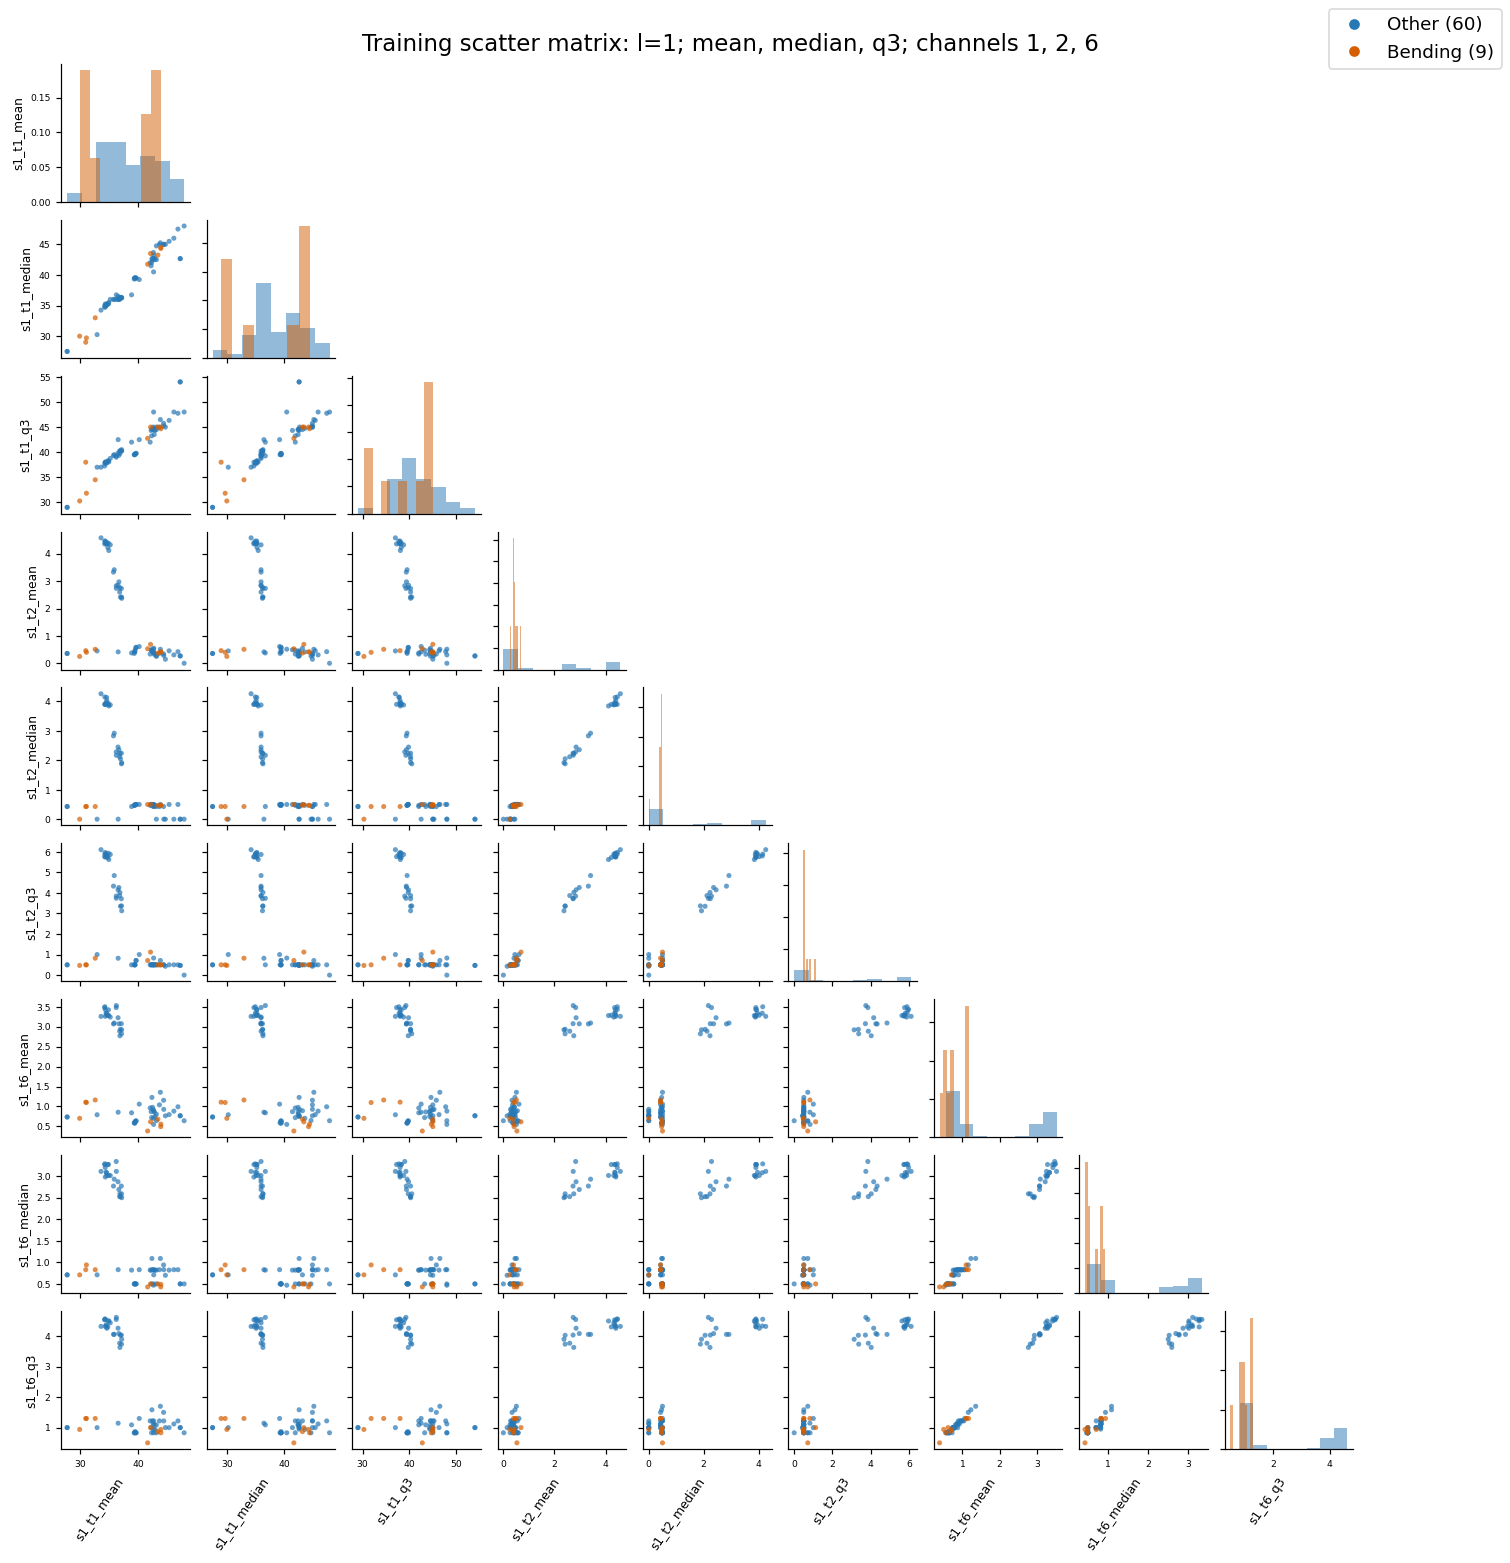

In [20]:
PLOT_METRICS = ['mean', 'median', 'q3']

def scatter_matrix(l):
    cols = [f's{s}_t{t}_{m}' for s in range(1,l+1) for t in (1,2,6) for m in PLOT_METRICS]
    data = feature_cache[l].iloc[train_idx][cols].to_numpy()
    d = len(cols)
    fig, axes = plt.subplots(d,d,figsize=(1.35*d+2,1.35*d+2))
    for i in range(d):
        for j in range(d):
            ax = axes[i,j]
            if j > i:
                ax.axis('off'); continue
            for cls, color in [(0,'#2878B5'), (1,'#D55E00')]:
                mask = y_train == cls
                if i == j:
                    ax.hist(data[mask,j], bins=8, color=color, alpha=.50, density=True)
                else:
                    ax.scatter(data[mask,j], data[mask,i], s=11, alpha=.7, color=color,
                               edgecolors='none')
            if i == d-1: ax.set_xlabel(cols[j], rotation=55, ha='right', fontsize=8)
            else: ax.set_xticklabels([])
            if j == 0: ax.set_ylabel(cols[i], fontsize=8)
            else: ax.set_yticklabels([])
            ax.tick_params(labelsize=6)
    from matplotlib.lines import Line2D
    handles = [Line2D([],[],marker='o',linestyle='',color=c,label=s)
               for c,s in [('#2878B5','Other (60)'),('#D55E00','Bending (9)')]]
    fig.legend(handles=handles,loc='upper right',fontsize=12)
    fig.suptitle(f'Training scatter matrix: l={l}; mean, median, q3; channels 1, 2, 6',fontsize=15)
    fig.subplots_adjust(top=.96,bottom=.07,left=.07,wspace=.13,hspace=.13)
    savefig(f'scatter_l{l}')
scatter_matrix(1)


## 2(a)(ii) — Split each channel into two halves
Each half contains 240 observations. There are now 12 channel-segment series
per recording and 84 candidate features. There are still 69 training examples.
In the plot below, s1 and s2 denote the two halves. Both halves of channels
1, 2, and 6 are shown, giving 18 plotted variables and all pairwise comparisons.


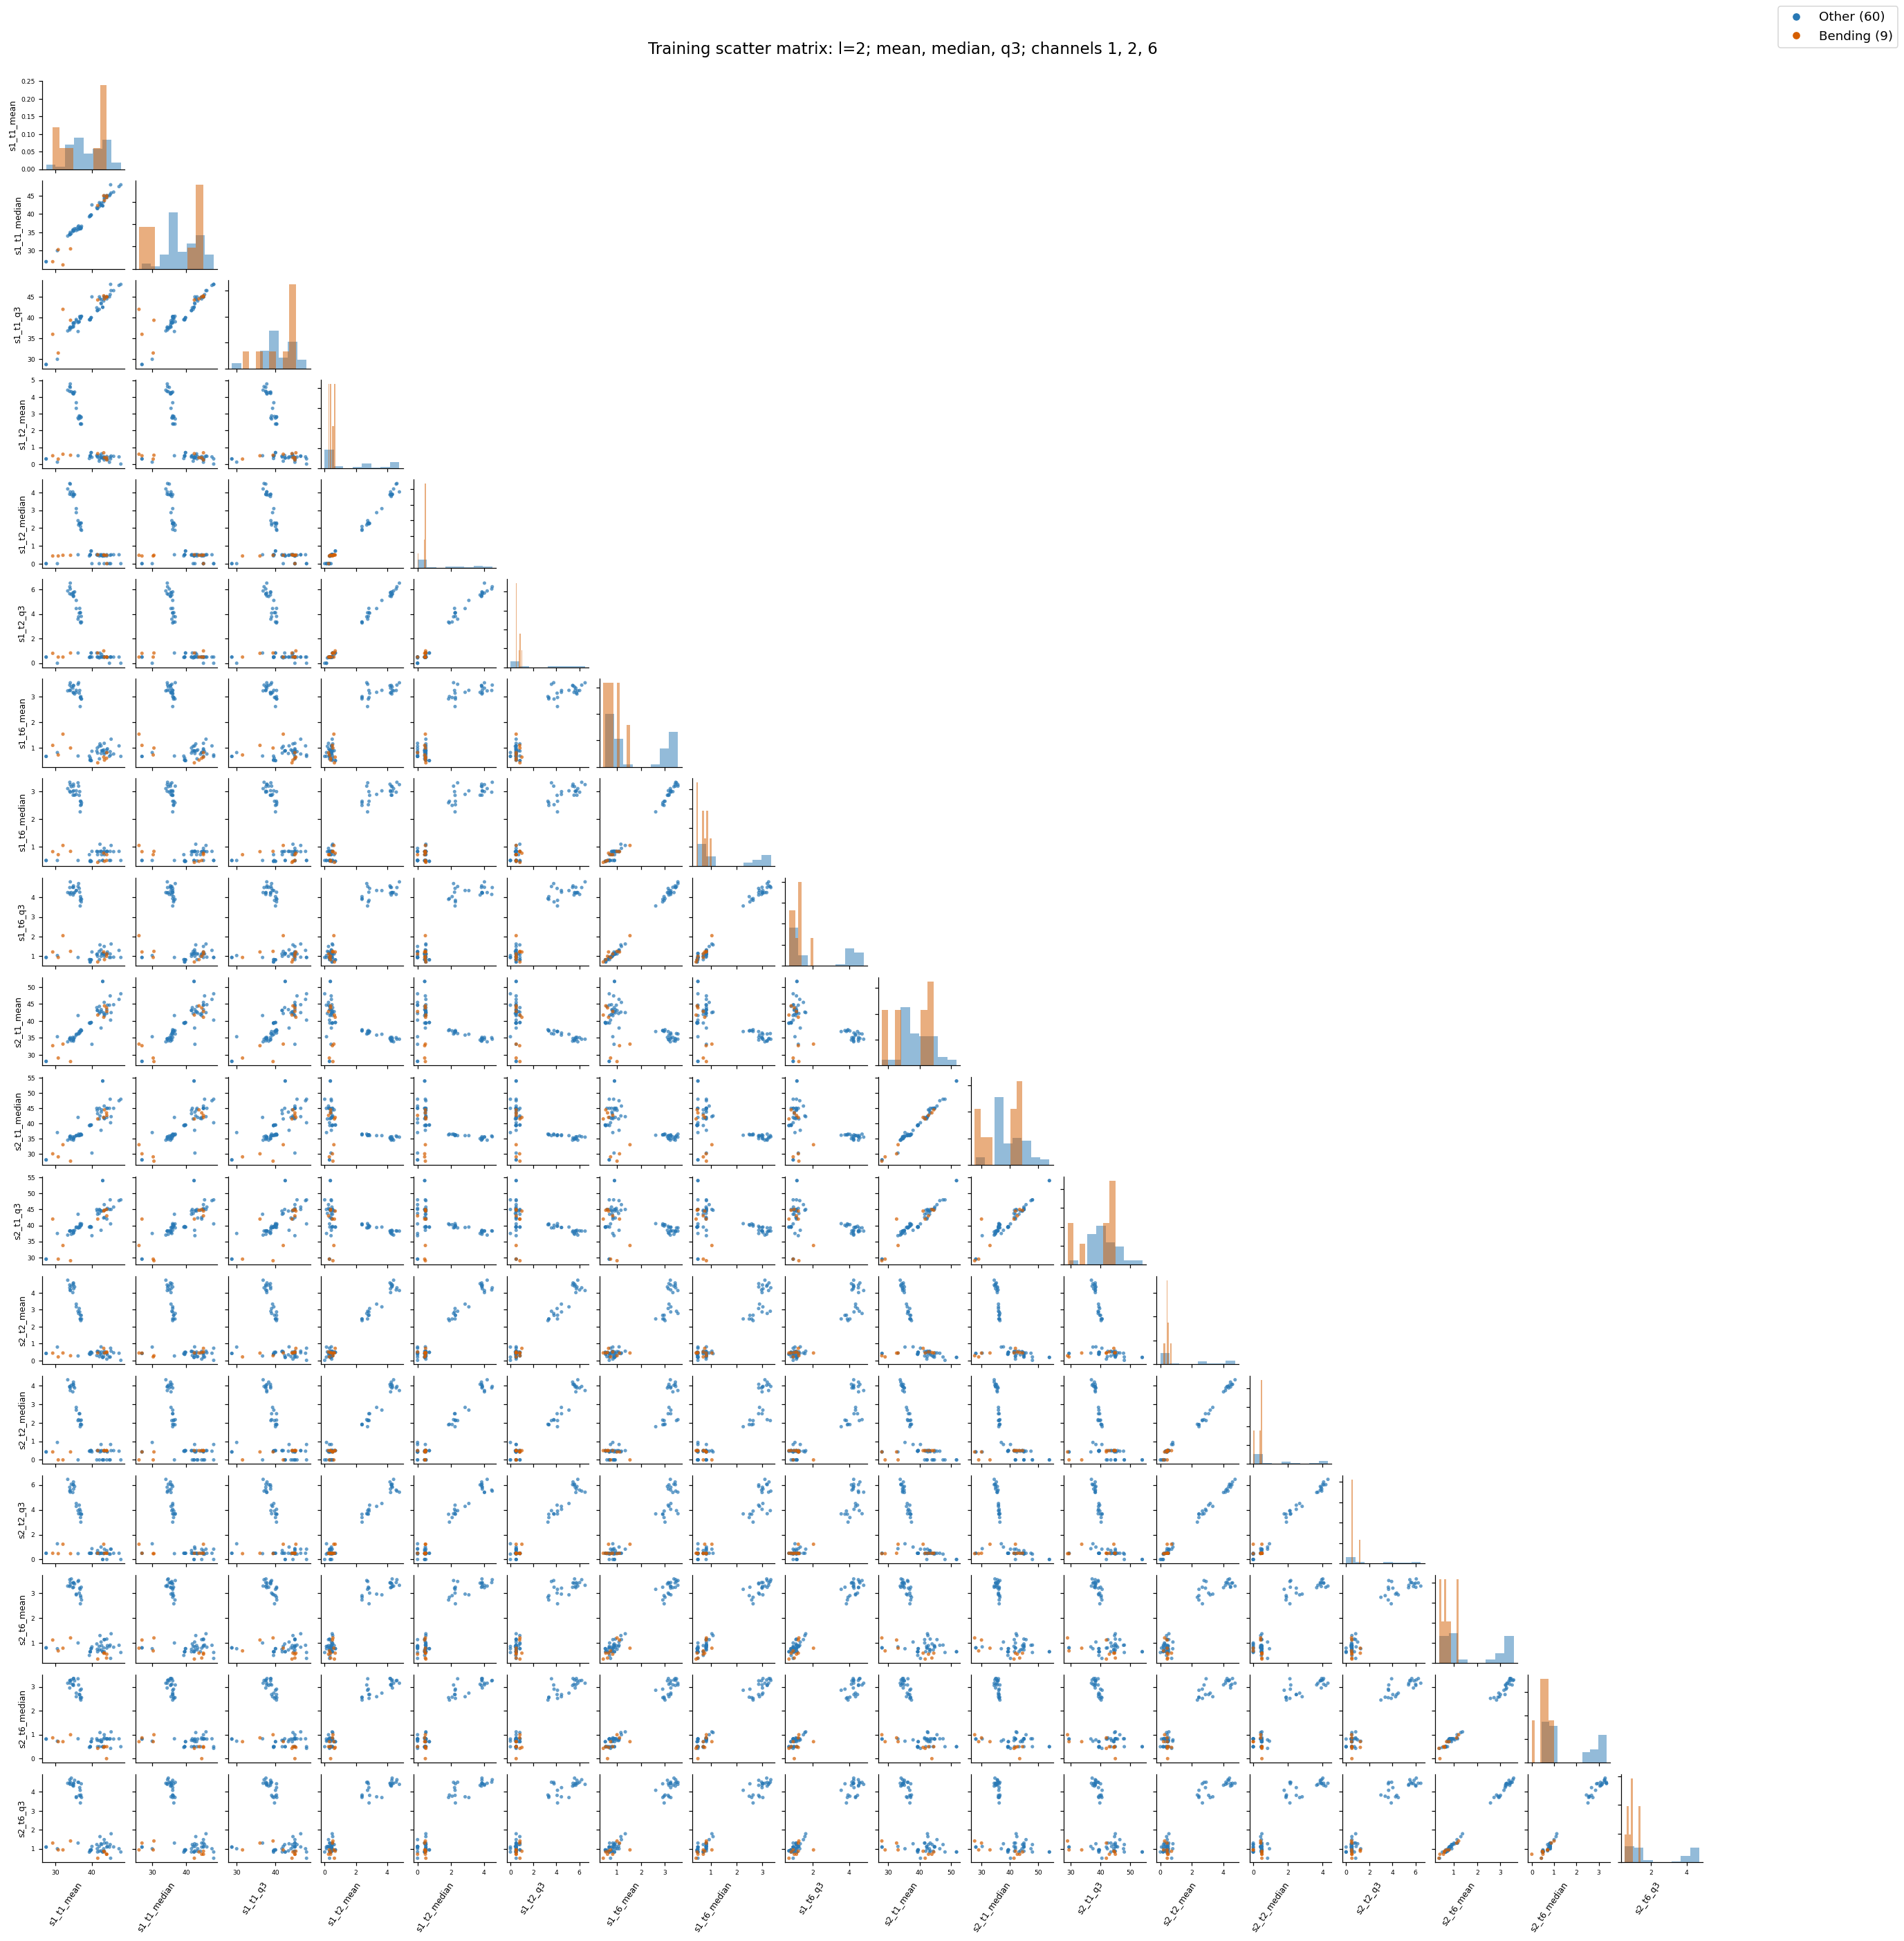

In [21]:
scatter_matrix(2)


### Answer to 2(a)(ii): comparison with unsplit series

There is **no dramatic visual improvement** after halving these selected
channels. In both matrices, bending recordings tend to have low values of
channel-2/channel-6 variation summaries, but other low-motion activities overlap
with them. Channel-1 mean, median, and q3 are strongly correlated, so many panels
repeat similar information. The halves add temporal variation and some clusters
shift, while substantial overlap remains. Visual overlap in two-dimensional
projections does not rule out separation in a larger set of features.

As a later numerical check, the best searched RFE mean CV accuracy at l=1 is
97.14%, compared with 95.71% at l=2. Thus this experiment does not support the
claim that simply splitting in half improves classification. The full l search
is still necessary because other segment counts can perform differently.


## 2(a)(iii) — Joint choice of l and feature count p
**Right cross-validation:** split recordings first. Within each fold fit the
scaler and backward feature selection on the fold's training recordings only.
Apply those fitted operations to its validation recordings. Keep all segments
from a recording in its one row. Use the same folds for all l and p values.

**Wrong cross-validation:** select features using all 69 labels before CV;
standardize using validation/test values; choose l from test accuracy; or treat
segments from one recording as separate independent rows in different folds.
Each leaks information or overstates the effective sample size.

StratifiedKFold approximately preserves the bending/other ratio. Five binary
validation folds have 1 or 2 bending examples each. Accuracy is the primary
assignment selection criterion; balanced accuracy and AUC are also reported.
The maximum CV score is a tuning score and may be optimistic after this search.
The untouched test set provides an independent evaluation.

We use the assignment's permitted **recursive backward elimination alternative**
to p-value pruning. We search every l=1,...,20 and p=1,...,20, plus p=30,42,60,
84,126,168,252,420,840 when available. The finite p grid is disclosed so that
'best' means best on this grid, rather than an exhaustive search over every p.
Start with all 42l features, fit logistic regression, remove the smallest squared
standardized coefficients, and refit. Batch removals are at most 10% of the
initial feature count and stop at each candidate p; below p=20 removal is one
feature at a time. Each p checkpoint is evaluated on the validation fold.
This reuses one elimination path per fold instead of recomputing shared steps.

Logistic fits use penalty=None, with no L2 regularization. Early convergence
at finite coefficients is a numerical stopping rule, not evidence that a finite
maximum likelihood estimate exists. Separation is checked explicitly later.


In [22]:
binary_folds = list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(np.zeros(69),y_train))
fold_counts = pd.DataFrame([{'fold':i+1,'fit_other':int((y_train[a]==0).sum()),
    'fit_bending':int((y_train[a]==1).sum()),'validation_other':int((y_train[b]==0).sum()),
    'validation_bending':int((y_train[b]==1).sum())} for i,(a,b) in enumerate(binary_folds)])
table(fold_counts,'binary_cv_fold_counts')

fit_warnings = []
def fit_record(model, X, y, context):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(X,y)
    for w in caught:
        if issubclass(w.category,ConvergenceWarning):
            fit_warnings.append({'context':context,'warning':str(w.message)})
    return model

def unpenalized():
    return LogisticRegression(penalty=None,solver='lbfgs',max_iter=2000,tol=1e-7,
                              random_state=SEED)

def p_grid(d):
    return sorted(set(range(1,21)) | {p for p in [30,42,60,84,126,168,252,420,840] if p<=d})

def backward_path(X,y,targets,context):
    active = np.arange(X.shape[1]); targets = set(targets)
    batch = max(1,int(.1*X.shape[1]))
    while True:
        model=fit_record(unpenalized(),X[:,active],y,context)
        d=len(active)
        if d in targets:
            yield d,active.copy(),model
        below=[p for p in targets if p<d]
        if not below: break
        remove=min(batch,d-max(below))
        importance=model.coef_[0]**2
        keep=np.ones(d,dtype=bool)
        keep[np.argsort(importance,kind='stable')[:remove]]=False
        active=active[keep]

start=time.time(); rfe_rows=[]
for l in range(1,21):
    X=feature_cache[l].iloc[train_idx].to_numpy()
    for fold,(a,b) in enumerate(binary_folds,1):
        scaler=StandardScaler().fit(X[a])
        A=scaler.transform(X[a]); B=scaler.transform(X[b])
        for p,cols,model in backward_path(A,y_train[a],p_grid(X.shape[1]),f'rfe_l{l}_fold{fold}'):
            pred=model.predict(B[:,cols]); prob=model.predict_proba(B[:,cols])[:,1]
            rfe_rows.append({'l':l,'p':p,'fold':fold,'accuracy':accuracy_score(y_train[b],pred),
                'balanced_accuracy':balanced_accuracy_score(y_train[b],pred),
                'auc':roc_auc_score(y_train[b],prob)})
    print(f'RFE: l={l:2d} complete ({time.time()-start:.1f}s)',flush=True)
rfe_folds=pd.DataFrame(rfe_rows)
rfe_folds.to_csv(OUT/'rfe_cv_folds.csv',index=False)
rfe_cv=rfe_folds.groupby(['l','p'],as_index=False).agg(
    mean_accuracy=('accuracy','mean'),sd_accuracy=('accuracy','std'),
    balanced_accuracy=('balanced_accuracy','mean'),auc=('auc','mean'))
# Round only for ties at numerical precision; prefer fewer features, then fewer segments.
rfe_cv['selection_score']=rfe_cv.mean_accuracy.round(12)
rfe_cv=rfe_cv.sort_values(['selection_score','p','l'],ascending=[False,True,True]).reset_index(drop=True)
best_rfe=rfe_cv.iloc[0]; rfe_l=int(best_rfe.l); rfe_p=int(best_rfe.p)
table(rfe_cv,'rfe_cv_grid')
print(f'Selected RFE l={rfe_l}, p={rfe_p}; mean 5-fold accuracy={best_rfe.mean_accuracy:.4f}')


,fold,fit_other,fit_bending,validation_other,validation_bending
0,1,48,7,12,2
1,2,48,7,12,2
2,3,48,7,12,2
3,4,48,7,12,2
4,5,48,8,12,1


RFE: l= 1 complete (0.1s)
RFE: l= 2 complete (0.3s)
RFE: l= 3 complete (0.5s)
RFE: l= 4 complete (0.7s)
RFE: l= 5 complete (0.8s)
RFE: l= 6 complete (1.0s)
RFE: l= 7 complete (1.2s)
RFE: l= 8 complete (1.4s)
RFE: l= 9 complete (1.6s)
RFE: l=10 complete (1.8s)
RFE: l=11 complete (2.0s)
RFE: l=12 complete (2.2s)
RFE: l=13 complete (2.5s)
RFE: l=14 complete (2.7s)
RFE: l=15 complete (2.9s)
RFE: l=16 complete (3.1s)
RFE: l=17 complete (3.3s)
RFE: l=18 complete (3.6s)
RFE: l=19 complete (3.8s)
RFE: l=20 complete (4.0s)


,l,p,mean_accuracy,sd_accuracy,balanced_accuracy,auc,selection_score
0,10,3,0.985714,0.031944,0.950000,0.908333,0.985714
1,3,1,0.971429,0.039123,0.941667,0.962500,0.971429
2,19,1,0.971429,0.039123,0.941667,0.983333,0.971429
3,10,2,0.971429,0.039123,0.900000,0.908333,0.971429
4,12,3,0.971429,0.039123,0.941667,0.933333,0.971429
5,10,4,0.971429,0.039123,0.941667,0.908333,0.971429
6,12,4,0.971429,0.039123,0.941667,0.933333,0.971429
7,18,4,0.971429,0.039123,0.941667,0.958333,0.971429
8,1,5,0.971429,0.039123,0.983333,0.991667,0.971429
9,10,5,0.971429,0.039123,0.941667,0.908333,0.971429


Showing first 30 of 540 rows; complete table: results/rfe_cv_grid.csv
Selected RFE l=10, p=3; mean 5-fold accuracy=0.9857


### Answer to 2(a)(iii): selected setting

The best searched pair is **(l,p)=(10,3)**. There are initially 420 candidate
features per recording at this l; backward selection retains three. The five
validation accuracies average **98.57%**, with a sample standard deviation of
**3.19 percentage points**. This is an unweighted mean of the five fold
accuracies; folds contain 13 or 14 recordings, so it need not equal the pooled
percentage of correct out-of-fold predictions. The chosen pair is refitted
below using all training recordings.


### Refit and summarize the selected classifier
All 69 training recordings can now be used to fit the scaler and repeat the
same backward selection path. Neither the selected segment count nor the
selected feature count is changed after viewing test results.
Coefficients below act on standardized features z=(x-training_mean)/training_sd.

A Wald approximation uses the observed information I=X' diag(p(1-p)) X and
SE=sqrt(diag(I^-1)); z=beta/SE and two-sided p=2 Phi(-|z|). These p-values
ignore feature selection and are only nominal even under regular conditions.
With complete separation the unpenalized finite MLE does not exist, and such
numerical p-values must not be treated as valid significance tests. We print
the finite solver output and its nominal calculation with that limitation.


In [23]:
Xr=feature_cache[rfe_l].iloc[train_idx].to_numpy()
rfe_scaler=StandardScaler().fit(Xr); Zr=rfe_scaler.transform(Xr)
for p,cols,model in backward_path(Zr,y_train,p_grid(Xr.shape[1]),'rfe_final'):
    if p==rfe_p:
        rfe_columns=cols; rfe_model=model; break
rfe_names=feature_cache[rfe_l].columns[rfe_columns].tolist()

def separation_check(Z,y):
    design=np.column_stack([np.ones(len(Z)),Z]); signed=2*y-1
    # Feasible iff a hyperplane gives a strictly positive margin for every row.
    lp=linprog(np.zeros(design.shape[1]),A_ub=-signed[:,None]*design,
        b_ub=-np.ones(len(y)),bounds=[(None,None)]*design.shape[1],method='highs')
    return bool(lp.success)

def wald_table(model,Z,names):
    D=np.column_stack([np.ones(len(Z)),Z]); prob=model.predict_proba(Z)[:,1]
    beta=np.r_[model.intercept_,model.coef_[0]]
    info=D.T @ ((prob*(1-prob))[:,None]*D)
    rank=np.linalg.matrix_rank(info); cond=np.linalg.cond(info)
    regular=(rank==D.shape[1] and cond<1e12)
    se=np.sqrt(np.maximum(0,np.diag(np.linalg.pinv(info)))) if regular else np.full(D.shape[1],np.nan)
    z=np.divide(beta,se,out=np.full_like(beta,np.nan),where=se>0)
    return pd.DataFrame({'term':['Intercept']+names,'coefficient':beta,
        'nominal_standard_error':se,'nominal_Wald_z':z,'nominal_p_value':2*norm.sf(abs(z))}),rank,cond

separated=separation_check(Zr[:,rfe_columns],y_train)
coef_table,info_rank,info_condition=wald_table(rfe_model,Zr[:,rfe_columns],rfe_names)
table(coef_table,'rfe_coefficients_nominal_pvalues')
print('Selected features:',rfe_names)
print('Strict linear separation feasible:',separated)
print('Information rank:',info_rank,'; condition number:',info_condition)
print('P-values are NOT reliable under separation or after selecting features on these labels.')


,term,coefficient,nominal_standard_error,nominal_Wald_z,nominal_p_value
0,Intercept,-38.069237,1046.750299,-0.036369,0.970988
1,s2_t5_q1,27.523712,701.865366,0.039215,0.968719
2,s3_t3_std,12.645221,1183.982541,0.010680,0.991479
3,s6_t1_max,-12.680559,1998.626605,-0.006345,0.994938


Selected features: ['s2_t5_q1', 's3_t3_std', 's6_t1_max']
Strict linear separation feasible: True
Information rank: 4 ; condition number: 165.32965165528717
P-values are NOT reliable under separation or after selecting features on these labels.


### Answer to 2(a)(iv): fitted coefficients and p-values

The finite solver output is

$$\eta=-38.0692+27.5237z_{s2,t5,q1}+12.6452z_{s3,t3,std}
-12.6806z_{s6,t1,max},\qquad P(bending\mid x)=
\frac{1}{1+e^{-\eta}}.$$

Here s denotes one of the ten chronological segments, t is the original channel,
and z denotes standardization with the full-training mean and scale. Channel 5
is avg_rss23, channel 3 is avg_rss13, and channel 1 is avg_rss12.

The nominal p-values are approximately 0.9710 for the intercept, 0.9687,
0.9915, and 0.9949 for the three features. **These are not valid evidence that
the features have no predictive value.** Strict separation is feasible, so
there is no finite unpenalized MLE; coefficients and estimated standard errors
can grow together. These are numerical Wald calculations at a finite stopping
point, also affected by prior feature selection. They cannot support ordinary
significance claims.


## 2(a)(iv)–(v) — Confusion matrices, ROC, AUC, and test accuracy
Rows in a confusion matrix are true labels; columns are predicted labels.
Bending is the positive class, so [[TN,FP],[FN,TP]] is the matrix order.
AUC uses probability scores and measures ranking; accuracy uses threshold 0.5.
Training metrics are resubstitution metrics and should not be called CV metrics.


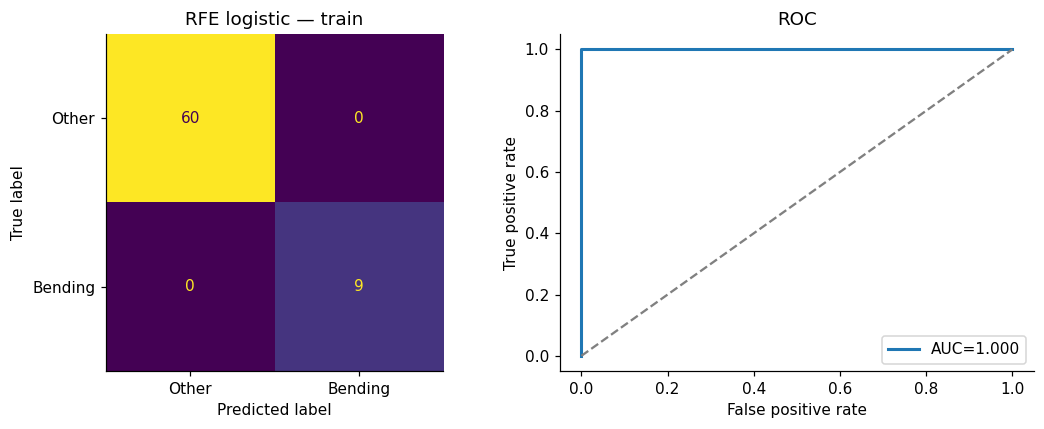

RFE logistic train {'model': 'RFE logistic', 'split': 'train', 'accuracy': 1.0, 'error': 0.0, 'balanced_accuracy': np.float64(1.0), 'auc': np.float64(0.9999999999999999), 'TN': 60, 'FP': 0, 'FN': 0, 'TP': 9}


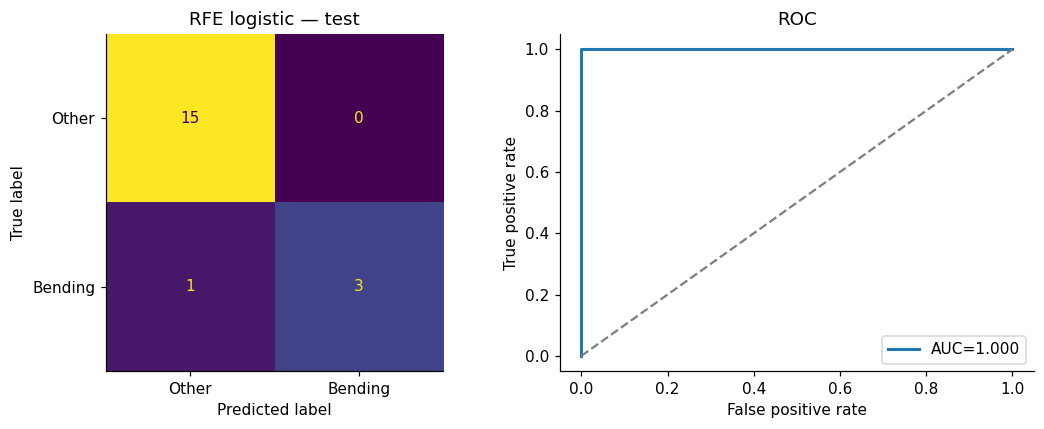

RFE logistic test {'model': 'RFE logistic', 'split': 'test', 'accuracy': 0.9473684210526315, 'error': 0.052631578947368474, 'balanced_accuracy': np.float64(0.875), 'auc': np.float64(1.0), 'TN': 15, 'FP': 0, 'FN': 1, 'TP': 3}
CV accuracy 0.9857; test accuracy 0.9474.
One test mistake changes accuracy by 0.05263157894736842 because there are only 19 test recordings.


In [24]:
binary_metrics=[]
def binary_report(name,split,y,prob):
    pred=(prob>=.5).astype(int); cm=confusion_matrix(y,pred,labels=[0,1])
    row={'model':name,'split':split,'accuracy':accuracy_score(y,pred),
         'error':1-accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),
         'auc':roc_auc_score(y,prob),'TN':int(cm[0,0]),'FP':int(cm[0,1]),
         'FN':int(cm[1,0]),'TP':int(cm[1,1])}
    binary_metrics.append(row)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    ConfusionMatrixDisplay(cm,display_labels=['Other','Bending']).plot(ax=axes[0],colorbar=False)
    axes[0].set_title(f'{name} — {split}')
    fpr,tpr,_=roc_curve(y,prob)
    axes[1].plot(fpr,tpr,label=f'AUC={row["auc"]:.3f}',lw=2)
    axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC')
    axes[1].legend(); fig.tight_layout(); savefig(name+'_'+split)
    print(name,split,row)
    return pred

rfe_train_prob=rfe_model.predict_proba(Zr[:,rfe_columns])[:,1]
rfe_test_X=feature_cache[rfe_l].iloc[test_idx].to_numpy()
rfe_test_prob=rfe_model.predict_proba(rfe_scaler.transform(rfe_test_X)[:,rfe_columns])[:,1]
rfe_train_pred=binary_report('RFE logistic','train',y_train,rfe_train_prob)
rfe_test_pred=binary_report('RFE logistic','test',y_test,rfe_test_prob)
print(f'CV accuracy {best_rfe.mean_accuracy:.4f}; test accuracy {accuracy_score(y_test,rfe_test_pred):.4f}.')
print('One test mistake changes accuracy by',1/19,'because there are only 19 test recordings.')


### Answer to 2(a)(v): train versus test

Training confusion matrix: **[[60,0],[0,9]]**, accuracy **100%**, AUC **1.00**.
Test confusion matrix: **[[15,0],[1,3]]**, accuracy **18/19=94.74%**, AUC **1.00**.
The missed bending case is **bending2/dataset2.csv**. Test accuracy is about
**3.83 percentage points below** the 98.57% mean CV tuning score.

AUC=1 does not imply accuracy=1 at threshold 0.5. The missed bending recording
still receives a higher probability than every other-activity recording, but
its probability is below the threshold. AUC evaluates ordering; the confusion
matrix depends on a specific threshold. Training accuracy is optimistic because
these recordings were used for fitting.


## 2(a)(vi) — Separation and coefficient instability
A strict separating hyperplane is checked with linear programming, not inferred
solely from an attractive scatter plot or a large AUC. If feasible, multiplying
its coefficients indefinitely makes the likelihood approach its supremum:
fitted probabilities approach the labels, while no finite maximum is attained.
Extra iterations can therefore enlarge coefficients rather than solve an
identification problem. L1 penalization makes a finite optimization problem.

For transparency, refit the selected variables at several convergence tolerances.
Stable predictions with changing coefficient norms illustrate why prediction
accuracy and coefficient inference are separate concerns. These diagnostic fits
are not used to change the selected classifier.


In [25]:
stability=[]
for tol in [1e-4,1e-7,1e-10]:
    diagnostic=fit_record(LogisticRegression(penalty=None,solver='lbfgs',max_iter=5000,tol=tol),
        Zr[:,rfe_columns],y_train,'separation_diagnostic')
    stability.append({'tolerance':tol,'coefficient_L2_norm':np.linalg.norm(diagnostic.coef_),
       'iterations':int(diagnostic.n_iter_[0]),
       'train_accuracy':diagnostic.score(Zr[:,rfe_columns],y_train)})
table(pd.DataFrame(stability),'separation_stability')


,tolerance,coefficient_L2_norm,iterations,train_accuracy
0,1.000000e-04,14.266868,13,1.0
1,1.000000e-07,32.836762,23,1.0
2,1.000000e-10,51.161744,34,1.0


### Answer to 2(a)(vi): observed instability

**Yes.** Linear programming finds a strict separating hyperplane for the selected
training variables. Tightening the solver tolerance from 1e-4 to 1e-7 to 1e-10
increases the coefficient norm from **14.27 to 32.84 to 51.16**, while training
accuracy stays 100%. This is the expected signature of separation: stable class
predictions can coexist with diverging coefficient estimates. A nominal large
p-value here reflects failed regular inference assumptions.


## 2(a)(vii) — Imbalance, case-control sampling, and prior correction
There are 60 controls (other) and 9 cases (bending) in training. A classifier
always predicting other already scores 60/69=86.96%; hence accuracy must be
read together with minority recall, balanced accuracy, and ROC/AUC.

We retain all nine cases and randomly sample nine controls, without replacement,
using a fixed seed. This is an actual balanced case-control sample. Fit a new
scaler and unpenalized logistic model on the selected feature coordinates in
that sample. The RFE l and feature list remain those already selected from
training. No test values are used in sampling or fitting.

Case-control sampling changes the class prior. If pi is the original training
prevalence and pi_s the sample prevalence, correct the intercept as
beta0_population = beta0_sample + logit(pi) - logit(pi_s).
Slopes are unchanged under ideal logistic sampling assumptions. Here pi=9/69
and pi_s=1/2. The formula corrects the artificial sampling odds; its calibration
benefit is uncertain with separation and only nine sampled controls. We show
both unadjusted and adjusted results. Intercept correction preserves ranking,
so its ROC/AUC is unchanged, though threshold predictions may change.


Sample cases/controls: 9 9
Intercept correction: -1.8971199848858813
Sample intercept: -0.8215570650507258 ; corrected intercept: -2.7186770499366073


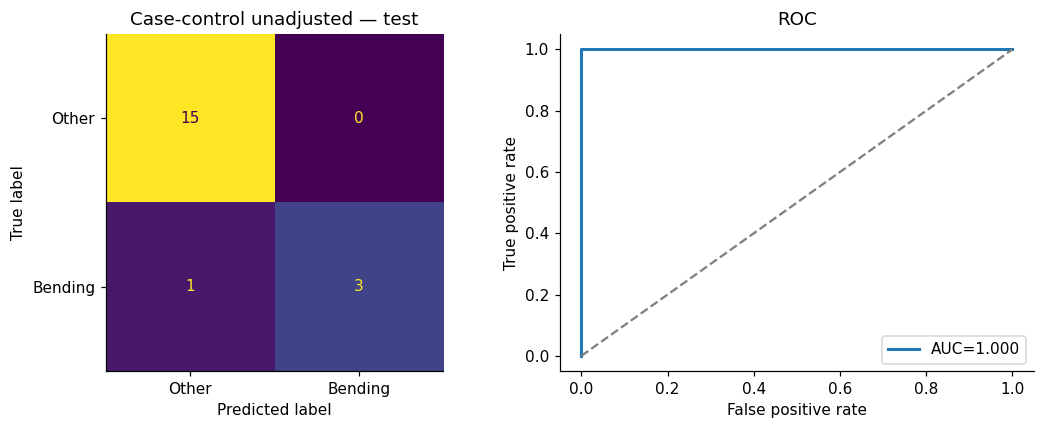

Case-control unadjusted test {'model': 'Case-control unadjusted', 'split': 'test', 'accuracy': 0.9473684210526315, 'error': 0.052631578947368474, 'balanced_accuracy': np.float64(0.875), 'auc': np.float64(1.0), 'TN': 15, 'FP': 0, 'FN': 1, 'TP': 3}


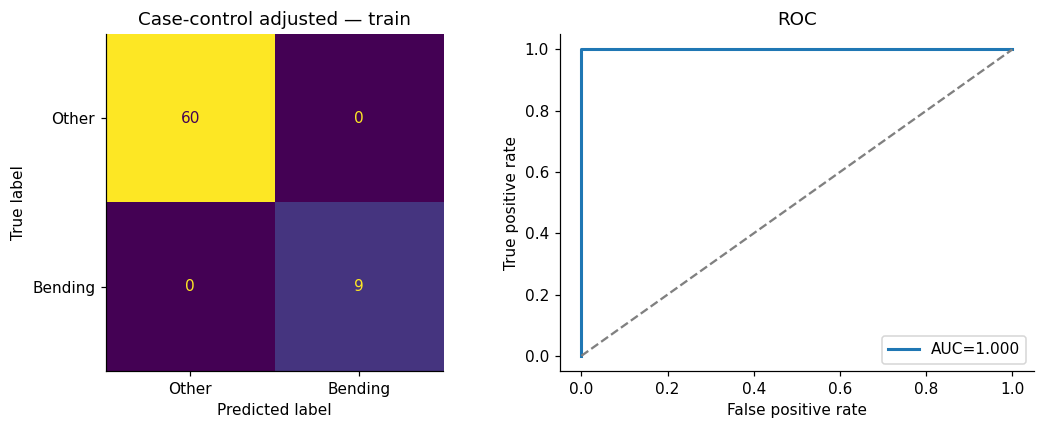

Case-control adjusted train {'model': 'Case-control adjusted', 'split': 'train', 'accuracy': 1.0, 'error': 0.0, 'balanced_accuracy': np.float64(1.0), 'auc': np.float64(1.0), 'TN': 60, 'FP': 0, 'FN': 0, 'TP': 9}


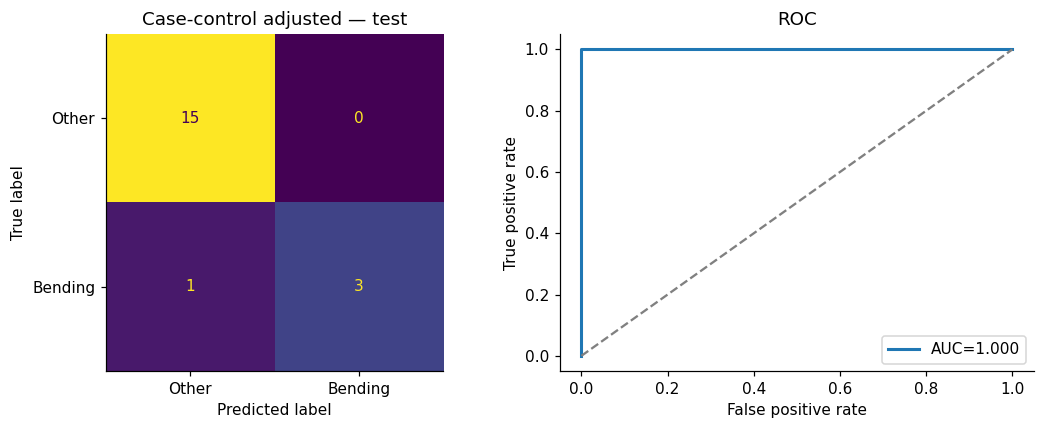

Case-control adjusted test {'model': 'Case-control adjusted', 'split': 'test', 'accuracy': 0.9473684210526315, 'error': 0.052631578947368474, 'balanced_accuracy': np.float64(0.875), 'auc': np.float64(1.0), 'TN': 15, 'FP': 0, 'FN': 1, 'TP': 3}


,term,sample_coefficient,population_coefficient
0,Intercept,-0.821557,-2.718677
1,s2_t5_q1,26.337660,26.337660
2,s3_t3_std,8.590367,8.590367
3,s6_t1_max,-7.963689,-7.963689


In [26]:
rng=np.random.default_rng(SEED)
case_indices=np.flatnonzero(y_train==1)
control_indices=rng.choice(np.flatnonzero(y_train==0),size=len(case_indices),replace=False)
cc_idx=np.r_[case_indices,control_indices]
cc_scaler=StandardScaler().fit(Xr[cc_idx][:,rfe_columns])
cc_model=fit_record(unpenalized(),cc_scaler.transform(Xr[cc_idx][:,rfe_columns]),y_train[cc_idx],'case_control')
prior_offset=logit(y_train.mean())-logit(y_train[cc_idx].mean())
print('Sample cases/controls:',int(y_train[cc_idx].sum()),int((y_train[cc_idx]==0).sum()))
print('Intercept correction:',prior_offset)
print('Sample intercept:',cc_model.intercept_[0],'; corrected intercept:',cc_model.intercept_[0]+prior_offset)
cc_test_scores=cc_model.decision_function(cc_scaler.transform(rfe_test_X[:,rfe_columns]))
cc_train_scores=cc_model.decision_function(cc_scaler.transform(Xr[:,rfe_columns]))
binary_report('Case-control unadjusted','test',y_test,expit(cc_test_scores))
binary_report('Case-control adjusted','train',y_train,expit(cc_train_scores+prior_offset))
binary_report('Case-control adjusted','test',y_test,expit(cc_test_scores+prior_offset))
table(pd.DataFrame({'term':['Intercept']+rfe_names,
    'sample_coefficient':np.r_[cc_model.intercept_,cc_model.coef_[0]],
    'population_coefficient':np.r_[cc_model.intercept_[0]+prior_offset,cc_model.coef_[0]]}),
    'case_control_parameters')


### Answer to 2(a)(vii): observed sampling results

The training majority baseline is **86.96%**, confirming meaningful imbalance.
Balancing produces 9 cases and 9 controls. The prior correction subtracts
**1.89712** from the sampled intercept, changing it from **-0.82156** to
**-2.71868** on this model's standardized scale.

The adjusted model has training matrix **[[60,0],[0,9]]**, AUC **1.00**. On test,
both sampled versions give **[[15,0],[1,3]]**, accuracy **94.74%**, balanced
accuracy **87.50%**, and AUC **1.00**. The correction changes probabilities but
no recording crosses the 0.5 threshold in this particular run, so its confusion
matrix is unchanged. Balancing therefore provides **no observed accuracy gain**
here; discarding controls also increases sampling variability. The correction
uses training prevalence as an estimate of the target prior.


## 2(b)(i) — L1-penalized binary logistic regression
Jointly search l=1,...,20 and C in {0.01,0.1,1,10,100}. Smaller C means stronger
regularization; it is the inverse penalty strength under the package's objective
convention, not a universal lambda independent of normalization. Standardization
is refitted in every training fold. liblinear handles the binary L1 objective.
A feature with coefficient exactly zero is excluded automatically.
Ties prefer smaller C (stronger shrinkage), then smaller l. All methods use
the same five binary folds and the same accuracy selection objective.


Binary L1: l=1 complete (0.0s)
Binary L1: l=2 complete (0.1s)
Binary L1: l=3 complete (0.1s)
Binary L1: l=4 complete (0.1s)
Binary L1: l=5 complete (0.1s)
Binary L1: l=6 complete (0.2s)
Binary L1: l=7 complete (0.2s)
Binary L1: l=8 complete (0.2s)
Binary L1: l=9 complete (0.3s)
Binary L1: l=10 complete (0.3s)
Binary L1: l=11 complete (0.3s)
Binary L1: l=12 complete (0.4s)
Binary L1: l=13 complete (0.4s)
Binary L1: l=14 complete (0.4s)
Binary L1: l=15 complete (0.5s)
Binary L1: l=16 complete (0.5s)
Binary L1: l=17 complete (0.6s)
Binary L1: l=18 complete (0.6s)
Binary L1: l=19 complete (0.7s)
Binary L1: l=20 complete (0.7s)


,l,C,mean_accuracy,sd_accuracy,balanced_accuracy,auc,mean_nonzero,selection_score
0,11,1.0,0.985714,0.031944,0.950000,0.933333,9.2,0.985714
1,12,1.0,0.985714,0.031944,0.950000,0.950000,9.2,0.985714
2,18,10.0,0.985714,0.031944,0.950000,0.941667,13.4,0.985714
3,19,100.0,0.985714,0.031944,0.950000,0.925000,14.8,0.985714
4,1,1.0,0.971429,0.039123,0.941667,0.975000,5.4,0.971429
5,13,1.0,0.971429,0.039123,0.900000,0.983333,10.0,0.971429
6,18,1.0,0.971429,0.039123,0.900000,0.983333,8.8,0.971429
7,19,1.0,0.971429,0.039123,0.900000,0.958333,9.0,0.971429
8,12,10.0,0.971429,0.063888,0.941667,0.958333,11.0,0.971429
9,19,10.0,0.971429,0.039123,0.900000,0.925000,12.6,0.971429


Showing first 30 of 100 rows; complete table: results/binary_l1_cv_grid.csv


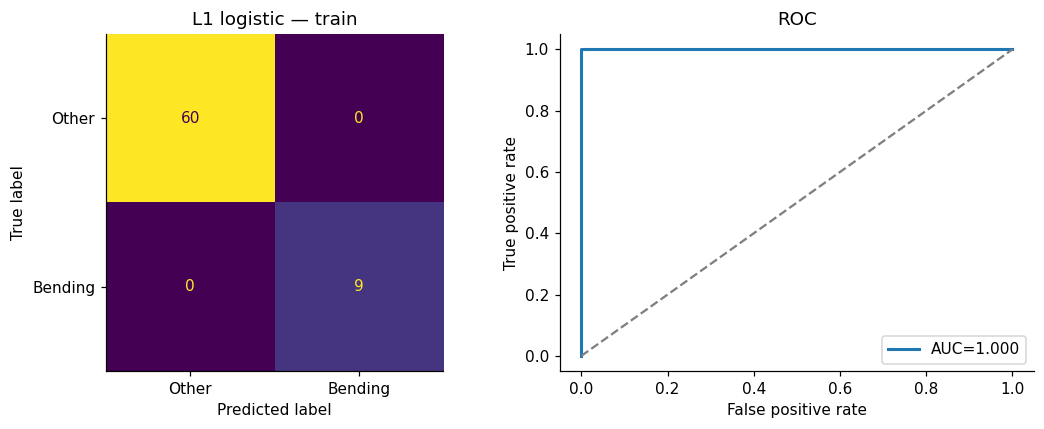

L1 logistic train {'model': 'L1 logistic', 'split': 'train', 'accuracy': 1.0, 'error': 0.0, 'balanced_accuracy': np.float64(1.0), 'auc': np.float64(1.0), 'TN': 60, 'FP': 0, 'FN': 0, 'TP': 9}


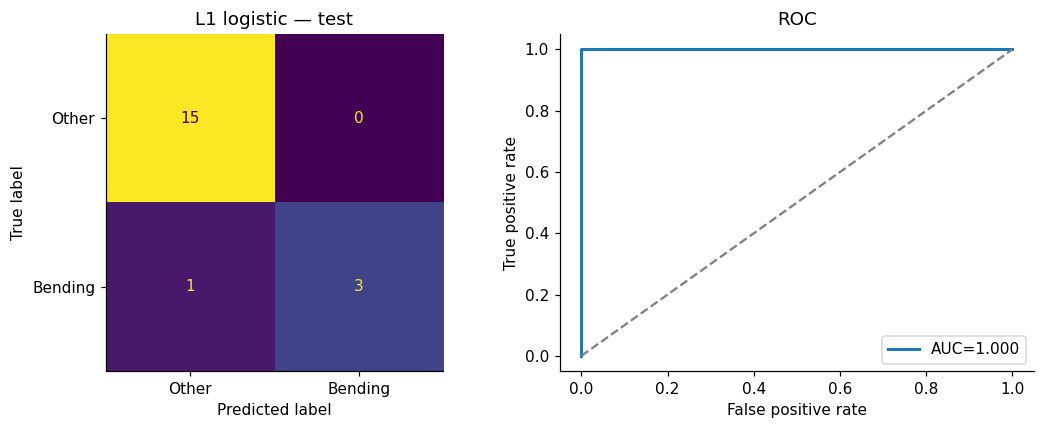

L1 logistic test {'model': 'L1 logistic', 'split': 'test', 'accuracy': 0.9473684210526315, 'error': 0.052631578947368474, 'balanced_accuracy': np.float64(0.875), 'auc': np.float64(1.0), 'TN': 15, 'FP': 0, 'FN': 1, 'TP': 3}


,feature,coefficient
29,s1_t5_max,0.253206
73,s2_t5_median,0.585027
75,s2_t5_q1,1.307961
211,s6_t1_max,-0.785927
318,s8_t4_median,-0.308930
375,s9_t6_std,-0.147170
406,s10_t5_min,0.721410
414,s10_t6_max,-0.033795


In [27]:
C_GRID=[.01,.1,1.,10.,100.]
l1_rows=[]; start=time.time()
for l in range(1,21):
    X=feature_cache[l].iloc[train_idx].to_numpy()
    for fold,(a,b) in enumerate(binary_folds,1):
        scaler=StandardScaler().fit(X[a]); A=scaler.transform(X[a]); B=scaler.transform(X[b])
        for C in C_GRID:
            m=fit_record(LogisticRegression(penalty='l1',solver='liblinear',C=C,
                max_iter=10000,tol=1e-6,random_state=SEED),A,y_train[a],f'binary_L1_l{l}_C{C}_fold{fold}')
            pred=m.predict(B); prob=m.predict_proba(B)[:,1]
            l1_rows.append({'l':l,'C':C,'fold':fold,'accuracy':accuracy_score(y_train[b],pred),
                'balanced_accuracy':balanced_accuracy_score(y_train[b],pred),
                'auc':roc_auc_score(y_train[b],prob),'nonzero':int(np.count_nonzero(m.coef_))})
    print(f'Binary L1: l={l} complete ({time.time()-start:.1f}s)',flush=True)
l1_folds=pd.DataFrame(l1_rows); l1_folds.to_csv(OUT/'binary_l1_cv_folds.csv',index=False)
l1_cv=l1_folds.groupby(['l','C'],as_index=False).agg(mean_accuracy=('accuracy','mean'),
    sd_accuracy=('accuracy','std'),balanced_accuracy=('balanced_accuracy','mean'),
    auc=('auc','mean'),mean_nonzero=('nonzero','mean'))
l1_cv['selection_score']=l1_cv.mean_accuracy.round(12)
l1_cv=l1_cv.sort_values(['selection_score','C','l'],ascending=[False,True,True]).reset_index(drop=True)
best_l1=l1_cv.iloc[0]; l1_l=int(best_l1.l); l1_C=float(best_l1.C)
table(l1_cv,'binary_l1_cv_grid')
l1_X=feature_cache[l1_l].iloc[train_idx].to_numpy()
l1_scaler=StandardScaler().fit(l1_X)
l1_model=fit_record(LogisticRegression(penalty='l1',solver='liblinear',C=l1_C,max_iter=10000,
    tol=1e-6,random_state=SEED),l1_scaler.transform(l1_X),y_train,'binary_l1_final')
l1_train_prob=l1_model.predict_proba(l1_scaler.transform(l1_X))[:,1]
l1_test_prob=l1_model.predict_proba(l1_scaler.transform(feature_cache[l1_l].iloc[test_idx].to_numpy()))[:,1]
binary_report('L1 logistic','train',y_train,l1_train_prob)
l1_test_pred=binary_report('L1 logistic','test',y_test,l1_test_prob)
table(pd.DataFrame({'feature':feature_cache[l1_l].columns,'coefficient':l1_model.coef_[0]}).query('coefficient != 0'),
      'binary_l1_nonzero_coefficients')


## 2(b)(ii) — Compare L1 and backward selection
The assignment allows backward selection instead of p-value pruning; that is
the alternative implemented here. A literal p-value pruning model would be
problematic when the unpenalized likelihood is separated and when p exceeds n.
Both selection methods require validation entirely inside the fitting fold.
L1 usually needs less selection code and shrinks correlated coefficients while
selecting them. The unpenalized RFE model does not shrink its retained variables.
The table compares CV tuning scores and untouched test accuracy/AUC. A test tie
does not establish equal generalization performance in the population.


In [28]:
binary_comparison=pd.DataFrame([
    {'method':'Unpenalized + backward RFE','l':rfe_l,'parameter':f'p={rfe_p}',
      'mean_CV_accuracy':best_rfe.mean_accuracy,'CV_sd':best_rfe.sd_accuracy,
      'test_accuracy':accuracy_score(y_test,rfe_test_pred),'test_auc':roc_auc_score(y_test,rfe_test_prob)},
    {'method':'L1 logistic','l':l1_l,'parameter':f'C={l1_C:g}',
      'mean_CV_accuracy':best_l1.mean_accuracy,'CV_sd':best_l1.sd_accuracy,
      'test_accuracy':accuracy_score(y_test,l1_test_pred),'test_auc':roc_auc_score(y_test,l1_test_prob)}])
table(binary_comparison,'binary_comparison')


,method,l,parameter,mean_CV_accuracy,CV_sd,test_accuracy,test_auc
0,Unpenalized + backward RFE,10,p=3,0.985714,0.031944,0.947368,1.0
1,L1 logistic,11,C=1,0.985714,0.031944,0.947368,1.0


### Answer to 2(b)(i)–(ii): selected L1 model and comparison

L1 selects **l=11, C=1**. Its mean five-fold CV accuracy is **98.57%**; its
training accuracy is **100%**, and its test accuracy is **94.74%**, AUC **1.00**.
It has the same test confusion matrix as backward RFE, **[[15,0],[1,3]]**.

Thus neither wins by mean CV accuracy or test accuracy in this run. L1 is easier
to implement because coefficient shrinkage and selection are part of a single
penalized fit. Backward selection requires repeated fits and a separate feature
count search. L1 also supplies finite penalized coefficients in the separated
setting; ordinary unpenalized p-value pruning would be unreliable here.


## 2(c)(i) — L1 multinomial logistic regression
We now distinguish all seven activities, including bending1 versus bending2.
This is a joint softmax model, not seven independently normalized binary fits.
SAGA supports the multinomial L1 objective; liblinear does not implement a joint
multinomial objective. Four stratified folds are used because bending2 has only
four training examples. Five folds could not place that activity in every
validation fold. The same four folds are used for all multiclass model families.

Search all l=1,...,20 and C in {0.01,0.1,1,10}. Features are standardized inside
each fold. SAGA uses tolerance 0.001 and up to 10000 iterations; all convergence
warnings are recorded. For efficiency, solutions are warm-started along C
within the SAME fitting fold; no state is shared across folds. Ties prefer
smaller C, then smaller l. The final estimator is refit from scratch.


In [29]:
classes=np.unique(y_multi_train)
multiclass_folds=list(StratifiedKFold(4,shuffle=True,random_state=SEED).split(np.zeros(69),y_multi_train))
MULTI_C_GRID=[.01,.1,1.,10.]
multi_rows=[]; start=time.time()
for l in range(1,21):
    X=feature_cache[l].iloc[train_idx].to_numpy()
    for fold,(a,b) in enumerate(multiclass_folds,1):
        scaler=StandardScaler().fit(X[a]); A=scaler.transform(X[a]); B=scaler.transform(X[b])
        m=LogisticRegression(penalty='l1',solver='saga',C=MULTI_C_GRID[0],max_iter=10000,
            tol=.001,random_state=SEED,warm_start=True)
        for C in MULTI_C_GRID:
            m.set_params(C=C)
            fit_record(m,A,y_multi_train[a],f'multinomial_l{l}_C{C}_fold{fold}')
            multi_rows.append({'l':l,'C':C,'fold':fold,'accuracy':m.score(B,y_multi_train[b]),
                'nonzero':int(np.count_nonzero(m.coef_)),'iterations':int(m.n_iter_[0])})
    print(f'Multinomial L1: l={l} complete ({time.time()-start:.1f}s)',flush=True)
multi_folds=pd.DataFrame(multi_rows);multi_folds.to_csv(OUT/'multinomial_cv_folds.csv',index=False)
multi_cv=multi_folds.groupby(['l','C'],as_index=False).agg(mean_accuracy=('accuracy','mean'),
    sd_accuracy=('accuracy','std'),mean_nonzero=('nonzero','mean'),max_iterations=('iterations','max'))
multi_cv['selection_score']=multi_cv.mean_accuracy.round(12)
multi_cv=multi_cv.sort_values(['selection_score','C','l'],ascending=[False,True,True]).reset_index(drop=True)
best_multi=multi_cv.iloc[0];multi_l=int(best_multi.l);multi_C=float(best_multi.C)
table(multi_cv,'multinomial_cv_grid')
multi_X=feature_cache[multi_l].iloc[train_idx].to_numpy()
multi_scaler=StandardScaler().fit(multi_X)
multi_model=fit_record(LogisticRegression(penalty='l1',solver='saga',C=multi_C,
    max_iter=10000,tol=.001,random_state=SEED),multi_scaler.transform(multi_X),y_multi_train,'multinomial_final')
multi_test_prob=multi_model.predict_proba(multi_scaler.transform(feature_cache[multi_l].iloc[test_idx].to_numpy()))


Multinomial L1: l=1 complete (0.1s)
Multinomial L1: l=2 complete (0.3s)
Multinomial L1: l=3 complete (0.7s)
Multinomial L1: l=4 complete (1.2s)
Multinomial L1: l=5 complete (1.8s)
Multinomial L1: l=6 complete (2.6s)
Multinomial L1: l=7 complete (3.4s)
Multinomial L1: l=8 complete (4.4s)
Multinomial L1: l=9 complete (5.5s)
Multinomial L1: l=10 complete (6.9s)
Multinomial L1: l=11 complete (8.4s)
Multinomial L1: l=12 complete (10.2s)
Multinomial L1: l=13 complete (11.9s)
Multinomial L1: l=14 complete (13.8s)
Multinomial L1: l=15 complete (15.8s)
Multinomial L1: l=16 complete (18.3s)
Multinomial L1: l=17 complete (20.8s)
Multinomial L1: l=18 complete (23.5s)
Multinomial L1: l=19 complete (26.6s)
Multinomial L1: l=20 complete (29.8s)


,l,C,mean_accuracy,sd_accuracy,mean_nonzero,max_iterations,selection_score
0,1,10.0,0.913399,0.032186,120.75,183,0.913399
1,2,10.0,0.913399,0.032186,260.25,131,0.913399
2,1,1.0,0.900327,0.081699,32.75,354,0.900327
3,2,1.0,0.886438,0.119549,50.00,421,0.886438
4,3,10.0,0.869281,0.030656,378.50,134,0.869281
5,14,10.0,0.868464,0.057747,2085.00,57,0.868464
6,4,10.0,0.854575,0.076850,527.00,95,0.854575
7,5,10.0,0.853758,0.060458,605.75,140,0.853758
8,15,10.0,0.840686,0.028160,2143.75,69,0.840686
9,15,1.0,0.826797,0.042859,275.50,427,0.826797


Showing first 30 of 80 rows; complete table: results/multinomial_cv_grid.csv


### Answer to 2(c)(i): selected multinomial model

The selected setting is **l=1, C=10**, mean four-fold CV accuracy **91.34%**.
The final model correctly labels **17/19** test recordings, giving accuracy
**89.47%** and test error **2/19=10.53%**. Its macro one-versus-rest AUC is
**0.9940**, and micro AUC is **0.9968**. The matrix and individual class curves
below show where the remaining mistakes occur. More segments did not improve
the best CV result enough to displace l=1 under the stated tie rule.


### Multiclass confusion matrices and ROC
A multiclass confusion matrix has one row and column per activity. Cell (i,j)
counts true class i classified as j. For each class k, a one-versus-rest ROC
treats k as positive and the other six classes as negative and varies the
threshold of P(Y=k). Macro AUC averages class AUCs equally. Micro AUC pools
all seven one-hot label columns and their scores before computing a single ROC.
Every test activity is represented, so each one-versus-rest AUC is defined.
Multiclass prediction itself is argmax of the seven probabilities.


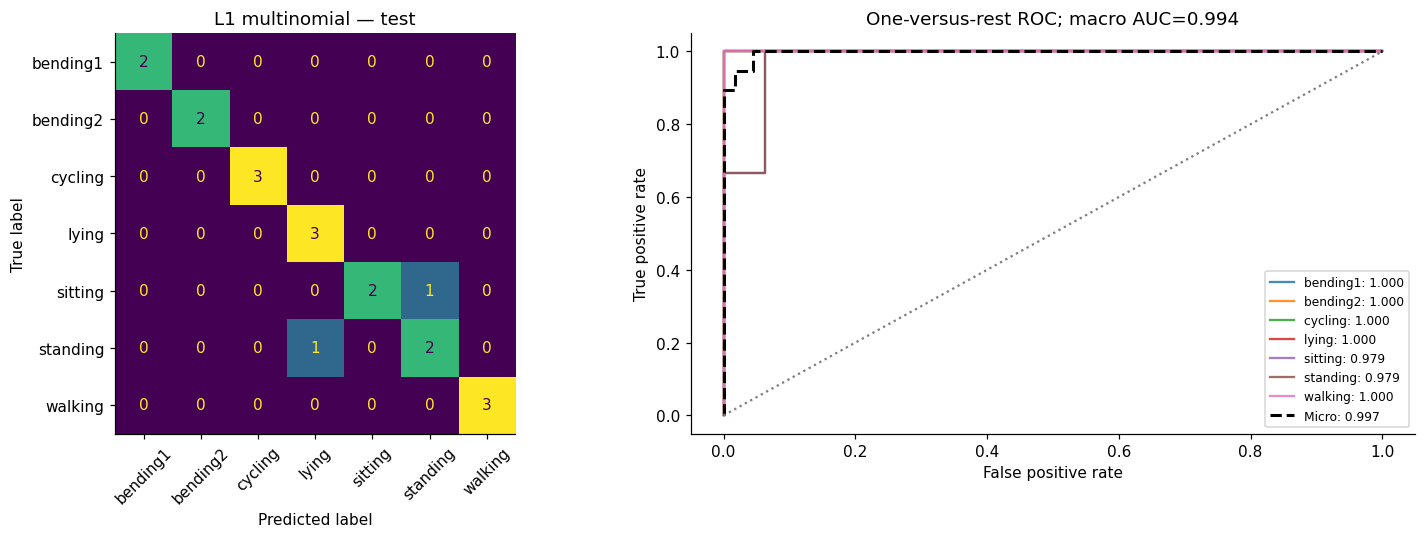

,class,precision,recall,f1-score,support
0,bending1,1.000000,1.000000,1.000000,2.000000
1,bending2,1.000000,1.000000,1.000000,2.000000
2,cycling,1.000000,1.000000,1.000000,3.000000
3,lying,0.750000,1.000000,0.857143,3.000000
4,sitting,1.000000,0.666667,0.800000,3.000000
5,standing,0.666667,0.666667,0.666667,3.000000
6,walking,1.000000,1.000000,1.000000,3.000000
7,accuracy,0.894737,0.894737,0.894737,0.894737
8,macro avg,0.916667,0.904762,0.903401,19.000000
9,weighted avg,0.907895,0.894737,0.893233,19.000000


,class,one_vs_rest_auc
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,1.000000
4,sitting,0.979167
5,standing,0.979167
6,walking,1.000000


{'model': 'L1 multinomial', 'test_accuracy': 0.8947368421052632, 'test_error': 0.10526315789473684, 'balanced_accuracy': np.float64(0.9047619047619049), 'macro_ovr_auc': 0.9940476190476192, 'micro_auc': np.float64(0.9967682363804247)}


In [30]:
multiclass_metrics=[]
def multiclass_report(name,prob):
    pred=classes[np.argmax(prob,axis=1)]
    cm=confusion_matrix(y_multi_test,pred,labels=classes)
    onehot=label_binarize(y_multi_test,classes=classes)
    aucs=[roc_auc_score(onehot[:,j],prob[:,j]) for j in range(len(classes))]
    micro=roc_auc_score(onehot.ravel(),prob.ravel())
    macro=float(np.mean(aucs))
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=axes[0],xticks_rotation=45,colorbar=False)
    axes[0].set_title(name+' — test')
    for j,cls in enumerate(classes):
        fpr,tpr,_=roc_curve(onehot[:,j],prob[:,j])
        axes[1].plot(fpr,tpr,label=f'{cls}: {aucs[j]:.3f}',alpha=.85)
    fpr,tpr,_=roc_curve(onehot.ravel(),prob.ravel())
    axes[1].plot(fpr,tpr,'k--',label=f'Micro: {micro:.3f}',lw=2)
    axes[1].plot([0,1],[0,1],':',color='gray')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',
        title=f'One-versus-rest ROC; macro AUC={macro:.3f}')
    axes[1].legend(fontsize=8);fig.tight_layout();savefig(name+'_multiclass_test')
    report=pd.DataFrame(classification_report(y_multi_test,pred,labels=classes,
        output_dict=True,zero_division=0)).T.reset_index(names='class')
    table(report,name+'_classification_report')
    table(pd.DataFrame({'class':classes,'one_vs_rest_auc':aucs}),name+'_class_auc')
    row={'model':name,'test_accuracy':accuracy_score(y_multi_test,pred),
        'test_error':1-accuracy_score(y_multi_test,pred),
        'balanced_accuracy':balanced_accuracy_score(y_multi_test,pred),
        'macro_ovr_auc':macro,'micro_auc':micro}
    multiclass_metrics.append(row);print(row)
    return pred
multi_pred=multiclass_report('L1 multinomial',multi_test_prob)


## 2(c)(ii) — Gaussian and Multinomial Naive Bayes
'Gaussian' and 'Multinomial' describe class-conditional feature likelihoods,
not two different class-prior distributions. Both models here estimate class
priors from the fitting fold. GaussianNB models each feature as normally
distributed conditional on class; features are conditionally independent.
MultinomialNB assumes nonnegative event counts (or count-like feature weights).
Continuous sensor summaries are not actual counts, so its likelihood is an
approximation in this problem, and it may perform poorly despite valid input.

For GaussianNB search l=1,...,20 and var_smoothing in {1e-11,1e-9,1e-7,1e-5}.
Fold-fitted standardization avoids arbitrary original feature units determining
the variance floor. For MultinomialNB use fold-fitted MinMaxScaler(clip=True)
to ensure nonnegative validation/test values without learning their ranges;
search alpha in {0.01,0.1,1,10}. A range [0,1] transformation gives fractional
nonnegative features, which the implementation accepts but does not turn these
summaries into genuinely generated multinomial counts. Clipping is disclosed.
No centered StandardScaler output is fed to MultinomialNB.


,family,l,parameter,mean_accuracy,sd_accuracy,selection_score
0,GaussianNB,1,1.000000e-07,0.884804,0.065216,0.884804
1,GaussianNB,1,1.000000e-05,0.870915,0.083253,0.870915
2,GaussianNB,1,1.000000e-11,0.870098,0.053922,0.870098
3,GaussianNB,1,1.000000e-09,0.870098,0.053922,0.870098
4,GaussianNB,2,1.000000e-11,0.856209,0.070999,0.856209
5,GaussianNB,2,1.000000e-09,0.856209,0.070999,0.856209
6,GaussianNB,2,1.000000e-07,0.856209,0.070999,0.856209
7,GaussianNB,2,1.000000e-05,0.856209,0.070999,0.856209
8,MultinomialNB,1,1.000000e-02,0.826797,0.142448,0.826797
9,MultinomialNB,10,1.000000e-01,0.825980,0.096183,0.825980


Showing first 30 of 160 rows; complete table: results/naive_bayes_cv_grid.csv


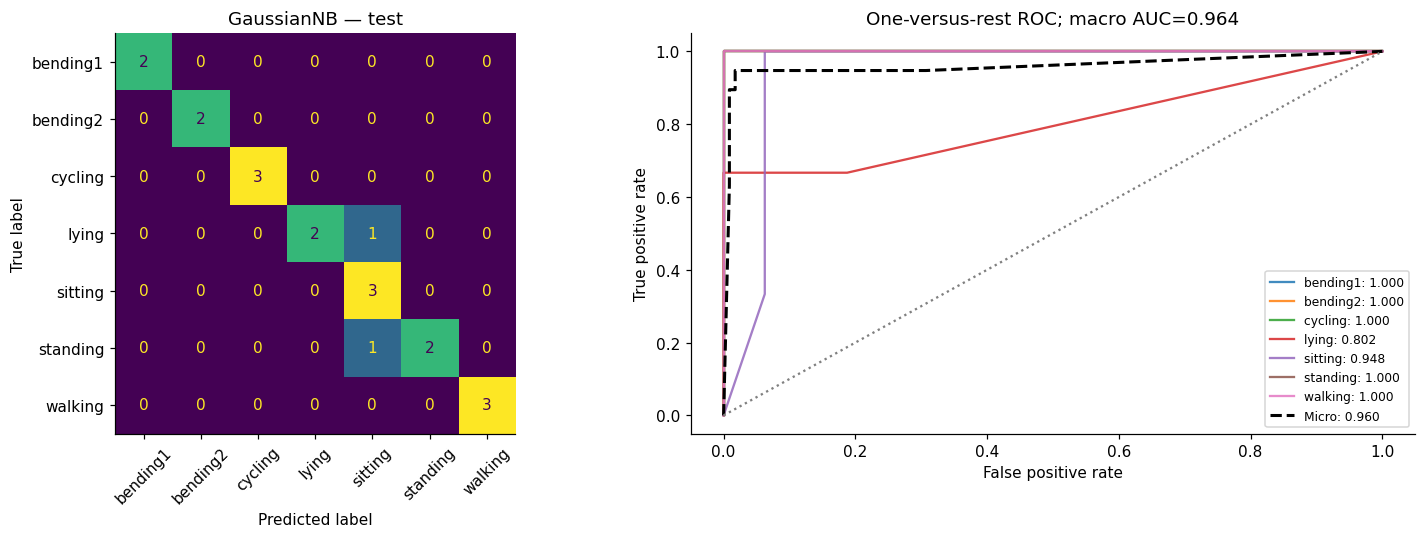

,class,precision,recall,f1-score,support
0,bending1,1.000000,1.000000,1.000000,2.000000
1,bending2,1.000000,1.000000,1.000000,2.000000
2,cycling,1.000000,1.000000,1.000000,3.000000
3,lying,1.000000,0.666667,0.800000,3.000000
4,sitting,0.600000,1.000000,0.750000,3.000000
5,standing,1.000000,0.666667,0.800000,3.000000
6,walking,1.000000,1.000000,1.000000,3.000000
7,accuracy,0.894737,0.894737,0.894737,0.894737
8,macro avg,0.942857,0.904762,0.907143,19.000000
9,weighted avg,0.936842,0.894737,0.897368,19.000000


,class,one_vs_rest_auc
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,0.802083
4,sitting,0.947917
5,standing,1.000000
6,walking,1.000000


{'model': 'GaussianNB', 'test_accuracy': 0.8947368421052632, 'test_error': 0.10526315789473684, 'balanced_accuracy': np.float64(0.9047619047619048), 'macro_ovr_auc': 0.9642857142857143, 'micro_auc': np.float64(0.9596029547553091)}


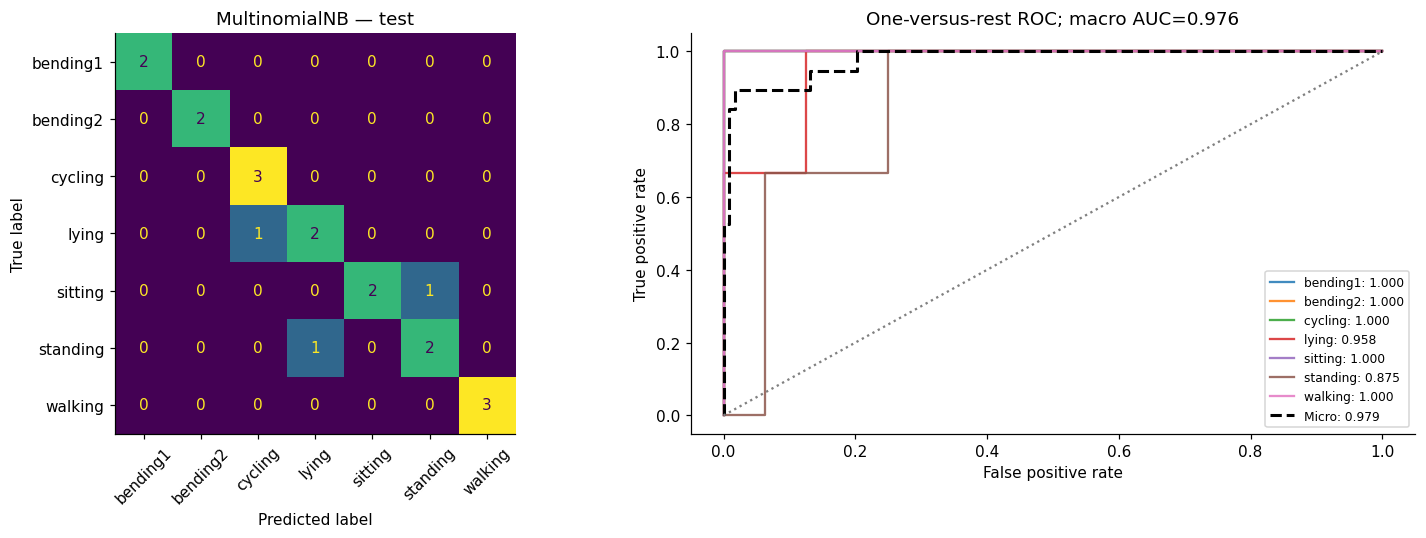

,class,precision,recall,f1-score,support
0,bending1,1.000000,1.000000,1.000000,2.000000
1,bending2,1.000000,1.000000,1.000000,2.000000
2,cycling,0.750000,1.000000,0.857143,3.000000
3,lying,0.666667,0.666667,0.666667,3.000000
4,sitting,1.000000,0.666667,0.800000,3.000000
5,standing,0.666667,0.666667,0.666667,3.000000
6,walking,1.000000,1.000000,1.000000,3.000000
7,accuracy,0.842105,0.842105,0.842105,0.842105
8,macro avg,0.869048,0.857143,0.855782,19.000000
9,weighted avg,0.855263,0.842105,0.840602,19.000000


,class,one_vs_rest_auc
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,0.958333
4,sitting,1.000000
5,standing,0.875000
6,walking,1.000000


{'model': 'MultinomialNB', 'test_accuracy': 0.8421052631578947, 'test_error': 0.1578947368421053, 'balanced_accuracy': np.float64(0.8571428571428571), 'macro_ovr_auc': 0.9761904761904763, 'micro_auc': np.float64(0.9787626962142197)}


In [31]:
nb_rows=[]
for l in range(1,21):
    X=feature_cache[l].iloc[train_idx].to_numpy()
    for fold,(a,b) in enumerate(multiclass_folds,1):
        for family,scaler,grid in [('GaussianNB',StandardScaler(),[1e-11,1e-9,1e-7,1e-5]),
                                    ('MultinomialNB',MinMaxScaler(clip=True),[.01,.1,1.,10.])]:
            A=scaler.fit_transform(X[a]);B=scaler.transform(X[b])
            for param in grid:
                m=GaussianNB(var_smoothing=param) if family=='GaussianNB' else MultinomialNB(alpha=param)
                m.fit(A,y_multi_train[a])
                nb_rows.append({'family':family,'l':l,'parameter':param,'fold':fold,
                                'accuracy':m.score(B,y_multi_train[b])})
nb_folds=pd.DataFrame(nb_rows);nb_folds.to_csv(OUT/'naive_bayes_cv_folds.csv',index=False)
nb_cv=nb_folds.groupby(['family','l','parameter'],as_index=False).agg(
    mean_accuracy=('accuracy','mean'),sd_accuracy=('accuracy','std'))
nb_cv['selection_score']=nb_cv.mean_accuracy.round(12)
nb_cv=nb_cv.sort_values(['selection_score','l','parameter'],ascending=[False,True,True]).reset_index(drop=True)
table(nb_cv,'naive_bayes_cv_grid')
nb_best={};nb_predictions={};nb_probabilities={}
for family in ['GaussianNB','MultinomialNB']:
    best=nb_cv[nb_cv.family==family].iloc[0];nb_best[family]=best
    l=int(best.l);param=float(best.parameter)
    X=feature_cache[l].iloc[train_idx].to_numpy()
    scaler=StandardScaler() if family=='GaussianNB' else MinMaxScaler(clip=True)
    A=scaler.fit_transform(X); B=scaler.transform(feature_cache[l].iloc[test_idx].to_numpy())
    m=GaussianNB(var_smoothing=param) if family=='GaussianNB' else MultinomialNB(alpha=param)
    m.fit(A,y_multi_train)
    assert np.array_equal(m.classes_,classes)
    prob=m.predict_proba(B)
    nb_probabilities[family]=prob
    nb_predictions[family]=multiclass_report(family,prob)


## 2(c)(iii) — Compare the multiclass methods
A lower test error is better on this held-out set. Compare the same four-fold
CV tuning accuracy too; test performance is not used to retune any model.
GaussianNB is cheap to fit but its conditional-independence assumption is
strained by correlated means, medians, and quartiles. MultinomialNB's count
likelihood is less natural for this sensor representation. L1 multinomial
regression learns class boundaries directly while controlling coefficient size.
With only 19 test examples, differences of one mistake are not conclusive
evidence of population-level superiority.


In [32]:
comparison=pd.DataFrame(multiclass_metrics)
comparison['selected_l']=[multi_l,int(nb_best['GaussianNB'].l),int(nb_best['MultinomialNB'].l)]
comparison['selected_parameter']=[f'C={multi_C:g}',
    f'var_smoothing={nb_best["GaussianNB"].parameter:g}',f'alpha={nb_best["MultinomialNB"].parameter:g}']
comparison['mean_CV_accuracy']=[best_multi.mean_accuracy,nb_best['GaussianNB'].mean_accuracy,
                               nb_best['MultinomialNB'].mean_accuracy]
comparison['CV_sd']=[best_multi.sd_accuracy,nb_best['GaussianNB'].sd_accuracy,nb_best['MultinomialNB'].sd_accuracy]
table(comparison,'multiclass_comparison')
print('Lowest test error:',comparison.loc[comparison.test_error.eq(comparison.test_error.min()),'model'].tolist())
print('Highest CV accuracy:',comparison.loc[comparison.mean_CV_accuracy.eq(comparison.mean_CV_accuracy.max()),'model'].tolist())


,model,test_accuracy,test_error,balanced_accuracy,macro_ovr_auc,micro_auc,selected_l,selected_parameter,mean_CV_accuracy,CV_sd
0,L1 multinomial,0.894737,0.105263,0.904762,0.994048,0.996768,1,C=10,0.913399,0.032186
1,GaussianNB,0.894737,0.105263,0.904762,0.964286,0.959603,1,var_smoothing=1e-07,0.884804,0.065216
2,MultinomialNB,0.842105,0.157895,0.857143,0.976190,0.978763,1,alpha=0.01,0.826797,0.142448


Lowest test error: ['L1 multinomial', 'GaussianNB']
Highest CV accuracy: ['L1 multinomial']


### Answers to 2(c)(ii)–(iii): which multiclass method is better?

GaussianNB selects **l=1, var_smoothing=1e-7** and achieves **17/19 correct**
(test error **10.53%**). MultinomialNB selects **l=1, alpha=0.01** and achieves
**16/19 correct** (test error **15.79%**). Their respective mean CV accuracies
are **88.48%** and **82.68%**.

**L1 multinomial regression is the preferred overall method in this run:** it
has the highest CV accuracy (**91.34%**) and ties GaussianNB for the lowest test
error. Its macro AUC (**0.9940**) also exceeds GaussianNB's (**0.9643**).
GaussianNB is a reasonable simpler competitor on this small test set. The
multinomial count likelihood is a less suitable assumption for these continuous
summaries, and it performs worse by both CV accuracy and test error here. All
three choose l=1, suggesting extra temporal splitting is not helpful for these
seven-class models under the searched settings.


## Search summaries and reproducibility checks
The plots show the best searched model per segment count, based on training
CV only. The saved grid CSVs retain every searched parameter combination and
the fold CSVs retain all individual validation scores.


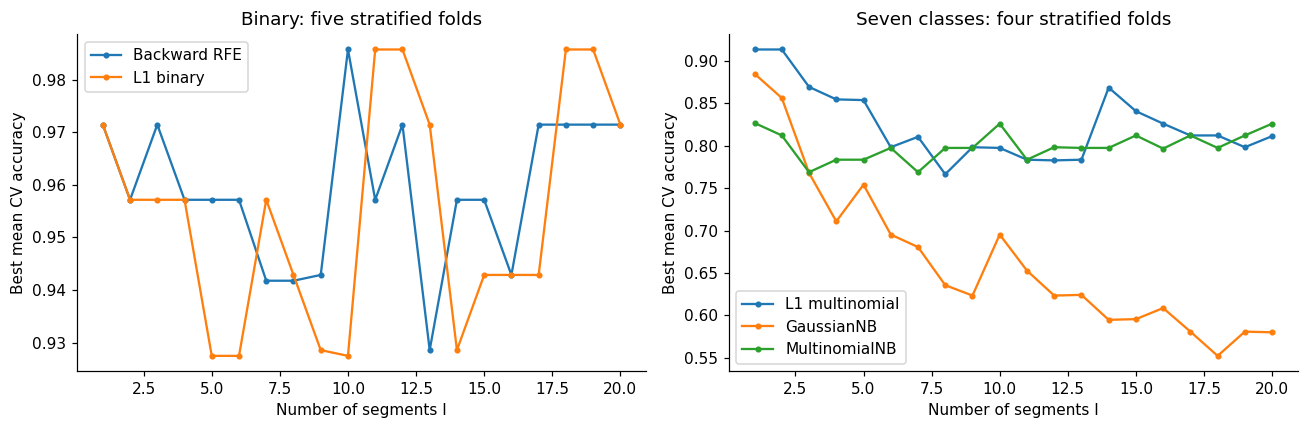

,model,split,accuracy,error,balanced_accuracy,auc,TN,FP,FN,TP
0,RFE logistic,train,1.000000,0.000000,1.000,1.0,60,0,0,9
1,RFE logistic,test,0.947368,0.052632,0.875,1.0,15,0,1,3
2,Case-control unadjusted,test,0.947368,0.052632,0.875,1.0,15,0,1,3
3,Case-control adjusted,train,1.000000,0.000000,1.000,1.0,60,0,0,9
4,Case-control adjusted,test,0.947368,0.052632,0.875,1.0,15,0,1,3
5,L1 logistic,train,1.000000,0.000000,1.000,1.0,60,0,0,9
6,L1 logistic,test,0.947368,0.052632,0.875,1.0,15,0,1,3


Convergence warnings: 0


,id,activity,binary_truth,rfe_bending_probability,rfe_prediction,l1_bending_probability,l1_prediction,multinomial_prediction,GaussianNB_prediction,MultinomialNB_prediction
0,bending1/dataset1.csv,bending1,1,1.000000e+00,1,0.997471,1,bending1,bending1,bending1
1,bending1/dataset2.csv,bending1,1,1.000000e+00,1,0.995551,1,bending1,bending1,bending1
7,bending2/dataset1.csv,bending2,1,1.000000e+00,1,0.973278,1,bending2,bending2,bending2
8,bending2/dataset2.csv,bending2,1,5.327845e-04,0,0.258547,0,bending2,bending2,bending2
13,cycling/dataset1.csv,cycling,0,6.688799e-12,0,0.065145,0,cycling,cycling,cycling
14,cycling/dataset2.csv,cycling,0,7.757492e-14,0,0.068990,0,cycling,cycling,cycling
15,cycling/dataset3.csv,cycling,0,3.939847e-05,0,0.067457,0,cycling,cycling,cycling
28,lying/dataset1.csv,lying,0,3.292432e-13,0,0.022117,0,lying,lying,cycling
29,lying/dataset2.csv,lying,0,1.964668e-33,0,0.001018,0,lying,sitting,lying
30,lying/dataset3.csv,lying,0,1.080673e-45,0,0.000790,0,lying,lying,lying


Verified: disjoint recording splits, 42l dimensions, finite features, valid probability sums.


In [33]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(rfe_cv.groupby('l').mean_accuracy.max(),label='Backward RFE',marker='o',ms=3)
axes[0].plot(l1_cv.groupby('l').mean_accuracy.max(),label='L1 binary',marker='o',ms=3)
axes[0].set(xlabel='Number of segments l',ylabel='Best mean CV accuracy',title='Binary: five stratified folds')
axes[0].legend()
axes[1].plot(multi_cv.groupby('l').mean_accuracy.max(),label='L1 multinomial',marker='o',ms=3)
for family in ['GaussianNB','MultinomialNB']:
    axes[1].plot(nb_cv[nb_cv.family==family].groupby('l').mean_accuracy.max(),label=family,marker='o',ms=3)
axes[1].set(xlabel='Number of segments l',ylabel='Best mean CV accuracy',title='Seven classes: four stratified folds')
axes[1].legend();fig.tight_layout();savefig('cv_accuracy_by_segment_count')
table(pd.DataFrame(binary_metrics),'binary_all_metrics')
warning_table=pd.DataFrame(fit_warnings,columns=['context','warning'])
warning_table.to_csv(OUT/'convergence_warnings.csv',index=False)
print('Convergence warnings:',len(fit_warnings))
if fit_warnings:
    display(warning_table.head(10))
# Store per-recording predictions to make the final counts auditable.
predictions=meta.iloc[test_idx][['id','activity']].copy()
predictions['binary_truth']=y_test
predictions['rfe_bending_probability']=rfe_test_prob
predictions['rfe_prediction']=rfe_test_pred
predictions['l1_bending_probability']=l1_test_prob
predictions['l1_prediction']=l1_test_pred
predictions['multinomial_prediction']=multi_pred
for family in nb_predictions: predictions[family+'_prediction']=nb_predictions[family]
table(predictions,'test_predictions')
assert all(set(a).isdisjoint(set(b)) for a,b in binary_folds)
assert all(set(a).isdisjoint(set(b)) for a,b in multiclass_folds)
assert set(train_idx).isdisjoint(set(test_idx))
assert np.allclose(multi_test_prob.sum(axis=1),1)
assert all(np.allclose(p.sum(axis=1),1) for p in nb_probabilities.values())
print('Verified: disjoint recording splits, 42l dimensions, finite features, valid probability sums.')


## 3. ISLR 4.8.3 — Why unequal Gaussian variances give a quadratic rule
Consider a one-dimensional predictor. In class k, let
$X\mid Y=k\sim N(\mu_k,\sigma_k^2)$ with prior $\pi_k$.
Bayes' rule selects the k maximizing $\pi_k f_k(x)$; the posterior denominator
is common to all classes. Taking logarithms and dropping the common
$-\frac12\log(2\pi)$ gives
$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$
Expand the square:
$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k.$$
The boundary between classes k and j satisfies $\delta_k(x)-\delta_j(x)=0$:
$$\left(\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}\right)x^2
+\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_j}{\sigma_j^2}\right)x
+\log\frac{\pi_k}{\pi_j}-\log\frac{\sigma_k}{\sigma_j}
-\frac{\mu_k^2}{2\sigma_k^2}+\frac{\mu_j^2}{2\sigma_j^2}=0.$$
Unequal variances generally give a nonzero quadratic coefficient, so the rule
is quadratic and can produce up to two boundary points in one dimension.
With equal variances, the $x^2$ terms cancel and the boundary reduces to a
linear equation. Special parameter choices can yield degenerate boundaries;
the statement is about the general unequal-variance rule, not that two real
roots must always exist. In higher dimensions this is quadratic discriminant
analysis, with terms involving $x^T\Sigma_k^{-1}x$.

## 4. ISLR 4.8.7 — Probability that a company issues a dividend
Let Y=Yes mean a dividend is issued, and X be last year's percent profit.
Given $\mu_{Yes}=10$, $\mu_{No}=0$, common $\sigma^2=36$,
$\pi_{Yes}=0.8$, $\pi_{No}=0.2$, find $P(Yes\mid X=4)$.

Bayes' rule gives
$$P(Yes\mid4)=\frac{0.8f_{Yes}(4)}{0.8f_{Yes}(4)+0.2f_{No}(4)}.$$
Since both densities have the factor $1/(\sqrt{2\pi}\,6)$, it cancels:
$$P(Yes\mid4)=\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}
=\frac{0.8e^{-1/2}}{0.8e^{-1/2}+0.2e^{-2/9}}
\approx0.75185.$$
Thus the estimated probability is **75.19%**, and the Bayes classifier with a
0.5 threshold predicts **Yes**. Although 4 is nearer to the No mean, the
much larger prior probability of Yes makes its posterior larger.
As a check, posterior log-odds are
$\log(0.8/0.2)+[16-36]/72=\log4-5/18\approx1.10852$;
the logistic function of this number gives the same result.


In [34]:
posterior=.8*np.exp(-((4-10)**2)/(2*36))/(.8*np.exp(-((4-10)**2)/(2*36))+.2*np.exp(-((4-0)**2)/(2*36)))
print(f'P(dividend=Yes | profit=4) = {posterior:.8f} = {100*posterior:.4f}%')
assert np.isclose(posterior,expit(np.log(4)-5/18))


P(dividend=Yes | profit=4) = 0.75185245 = 75.1852%


## References
- Assignment: Homework4.pdf, DSCI 552, Mohammad Reza Rajati, sections 2–4.
- UCI AReM dataset: https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem
- James, Witten, Hastie, Tibshirani (2021), *An Introduction to Statistical
  Learning*, second edition, Chapter 4, exercises 3 and 7:
  https://www.statlearning.com/ (official book download).
- scikit-learn 1.8 LogisticRegression solver/penalty documentation:
  https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html
- Cross-validation and feature-selection leakage:
  https://scikit-learn.org/stable/common_pitfalls.html#data-leakage
- Recursive feature elimination:
  https://scikit-learn.org/stable/modules/feature_selection.html#recursive-feature-elimination
- GaussianNB and MultinomialNB assumptions:
  https://scikit-learn.org/stable/modules/naive_bayes.html
- Case-control prior correction: Prentice & Pyke (1979), *Logistic disease
  incidence models and case-control studies*, Biometrika 66(3), 403–411,
  https://doi.org/10.1093/biomet/66.3.403

Extra-practice exercises 4.8.4 and 4.8.9 are explicitly not required for submission.
